# Traffic Sign Detection Using CNN
# By: Suchitra Thanumalayan

- **Part 1:** Data Analysis report: what the traffic sign images look like (size, quality, colour, shape) and what makes the classes easy or hard to separate
- **Part 2:** Predictive Model: a **Convolutional Neural Network (CNN)** that looks at a picture of a traffic sign and says **which of the 43 types of sign** it is
- **Part 3:** Suggestions on how to use the model in a real driver-assistance system
- **Part 4:** Model Comparison Report and Challenges

## Project Goal
Create a model that can **recognise the type of traffic sign** in a picture (speed limit 50, stop, yield, no entry, ...). This is the step a self-driving car or a driver-assistance system needs after a camera has found a sign on the road.

## Data Source
The data is the folder **`PRAICP-1002-TrafSignDetc.zip`** (642 MB). It is the **German Traffic Sign Recognition Benchmark (GTSRB)**:
- `Train/0` ... `Train/42`: **43 folders, one per sign type**, with the training images (PNG).
- `Test/`: the test images, with their correct class in `Test.csv`.
- `Train.csv` / `Test.csv`: for every image its **width, height**, the **box around the sign** (`Roi.X1, Roi.Y1, Roi.X2, Roi.Y2`) and the **ClassId** (0-42).
- `Meta/` and `Meta.csv`: one clean drawing of each of the 43 signs, with its **shape** and **colour** code.

The pictures were cut out of videos filmed from a car driving on German roads, so they come with different light, distance, blur and weather. The zip contains every folder twice (`Train` and `train`, `Test` and `test`, `Meta` and `meta`). The two copies were checked and are **exactly the same** (same CRC for every file), so only the upper-case folders were extracted into `traffic_data/`.

## Tools
- **PyTorch + torchvision** to build and train the CNNs. The laptop has an **Intel Arc 140V GPU**, which PyTorch uses as device `xpu`.
- pandas, matplotlib, seaborn and scikit-learn for the analysis, the tables and the metrics.

In [1]:
import os, io, time, hashlib, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

DATA_DIR = 'traffic_data'       # extracted PRAICP-1002-TrafSignDetc.zip
CACHE_DIR = 'traffic_cache'     # resized images and image details (made once)
MODEL_DIR = 'traffic_models'    # trained models and their training history
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = 'xpu' if torch.xpu.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch', torch.__version__, '| device:', device, '|', torch.xpu.get_device_name(0) if device == 'xpu' else '')

PyTorch 2.8.0+xpu | device: xpu | Intel(R) Arc(TM) 140V GPU (16GB)


In [2]:
# the zip has no file with the sign names, so they are written here (official GTSRB names, ClassId 0-42)
SIGN_NAMES = ['Speed limit 20', 'Speed limit 30', 'Speed limit 50', 'Speed limit 60', 'Speed limit 70',
              'Speed limit 80', 'End of speed limit 80', 'Speed limit 100', 'Speed limit 120', 'No passing',
              'No passing for trucks', 'Right-of-way at next crossing', 'Priority road', 'Yield', 'Stop',
              'No vehicles', 'Trucks prohibited', 'No entry', 'General caution', 'Dangerous curve left',
              'Dangerous curve right', 'Double curve', 'Bumpy road', 'Slippery road', 'Road narrows on the right',
              'Road work', 'Traffic signals', 'Pedestrians', 'Children crossing', 'Bicycles crossing',
              'Beware of ice / snow', 'Wild animals crossing', 'End of all limits', 'Turn right ahead',
              'Turn left ahead', 'Ahead only', 'Go straight or right', 'Go straight or left', 'Keep right',
              'Keep left', 'Roundabout', 'End of no passing', 'End of no passing for trucks']

train_csv = pd.read_csv(os.path.join(DATA_DIR, 'Train.csv'))
test_csv = pd.read_csv(os.path.join(DATA_DIR, 'Test.csv'))
meta = pd.read_csv(os.path.join(DATA_DIR, 'Meta.csv'))
train_csv['Set'], test_csv['Set'] = 'Train', 'Test'
df = pd.concat([train_csv, test_csv], ignore_index=True)
df['Path'] = DATA_DIR + '/' + df['Path']
print('Train images:', len(train_csv), '| Test images:', len(test_csv), '| Sign classes:', df['ClassId'].nunique())
df.head()

Train images: 39209 | Test images: 12630 | Sign classes: 43


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path,Set
0,27,26,5,5,22,20,20,traffic_data/Train/20/00020_00000_00000.png,Train
1,28,27,5,6,23,22,20,traffic_data/Train/20/00020_00000_00001.png,Train
2,29,26,6,5,24,21,20,traffic_data/Train/20/00020_00000_00002.png,Train
3,28,27,5,6,23,22,20,traffic_data/Train/20/00020_00000_00003.png,Train
4,28,26,5,5,23,21,20,traffic_data/Train/20/00020_00000_00004.png,Train


In [3]:
meta.sort_values('ClassId').head(10)

,Path,ClassId,ShapeId,ColorId,SignId
1,Meta/0.png,0,1,0,3.29
2,Meta/1.png,1,1,0,3.29
13,Meta/2.png,2,1,0,3.29
23,Meta/3.png,3,1,0,3.29
34,Meta/4.png,4,1,0,3.29
38,Meta/5.png,5,1,0,3.29
39,Meta/6.png,6,1,3,3.3
40,Meta/7.png,7,1,0,3.29
41,Meta/8.png,8,1,0,3.29
42,Meta/9.png,9,1,0,3.25


# Part 1: Data Analysis Report
## 1. Basic Checks

In [4]:
df.shape

(51839, 9)

In [5]:
# are the CSV files and the image folders the same?
files_on_disk = sum(len(f) for _, _, f in os.walk(os.path.join(DATA_DIR, 'Train'))) + \
                len([f for f in os.listdir(os.path.join(DATA_DIR, 'Test')) if f.endswith('.png')])
print('PNG files on disk:', files_on_disk, '| rows in Train.csv + Test.csv:', len(df))
print('Every path in the CSVs exists:', df['Path'].map(os.path.exists).all())
print('Other files in Test/:', [f for f in os.listdir(os.path.join(DATA_DIR, 'Test')) if not f.endswith('.png')])

PNG files on disk: 51839 | rows in Train.csv + Test.csv: 51839


Every path in the CSVs exists: True
Other files in Test/: ['GT-final_test.csv']


In [6]:
df.groupby('Set')['ClassId'].value_counts().unstack(0).describe()

Set,Test,Train
count,43.000000,43.000000
mean,293.720930,911.837209
std,233.442389,695.856715
min,60.000000,210.000000
25%,90.000000,345.000000
50%,180.000000,600.000000
75%,450.000000,1425.000000
max,750.000000,2250.000000


In [7]:
df['Path'].str.split('.').str[-1].value_counts()

Path
png    51839
Name: count, dtype: int64

In [8]:
# read every file once: real width, height, colour mode, format, file size and a fingerprint (MD5)
# the MD5 is the same for two files only if they are exactly the same image -> finds duplicates
def image_info(path):
    with open(path, 'rb') as fh:
        data = fh.read()
    try:
        im = Image.open(io.BytesIO(data))
        w, h, mode, fmt = im.size[0], im.size[1], im.mode, im.format
    except Exception:
        w, h, mode, fmt = np.nan, np.nan, 'ERROR', 'ERROR'
    return w, h, mode, fmt, len(data) / 1024, hashlib.md5(data).hexdigest()

INFO_FILE = os.path.join(CACHE_DIR, 'image_info.csv')
if os.path.exists(INFO_FILE):
    info = pd.read_csv(INFO_FILE)
else:
    with ThreadPoolExecutor(8) as ex:
        info = pd.DataFrame(list(ex.map(image_info, df['Path'])),
                            columns=['Real Width', 'Real Height', 'Mode', 'Format', 'File KB', 'MD5'])
    info.to_csv(INFO_FILE, index=False)
df = pd.concat([df, info], axis=1)
print('Width / Height in the CSV equal to the real image size:',
      ((df['Width'] == df['Real Width']) & (df['Height'] == df['Real Height'])).all())
df = df.drop(columns=['Real Width', 'Real Height'])
df.head()

Width / Height in the CSV equal to the real image size: True


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path,Set,Mode,Format,File KB,MD5
0,27,26,5,5,22,20,20,traffic_data/Train/20/00020_00000_00000.png,Train,RGB,PNG,1.330078,7dc256a8b7ba34de27b57875f41dab7b
1,28,27,5,6,23,22,20,traffic_data/Train/20/00020_00000_00001.png,Train,RGB,PNG,1.445312,11c4aeb2e7a0932b2eec08afa7232981
2,29,26,6,5,24,21,20,traffic_data/Train/20/00020_00000_00002.png,Train,RGB,PNG,1.379883,19561c85ee07fdc8f26258cabfcaed62
3,28,27,5,6,23,22,20,traffic_data/Train/20/00020_00000_00003.png,Train,RGB,PNG,1.417969,a13019c2f35cdf49866be199593a515a
4,28,26,5,5,23,21,20,traffic_data/Train/20/00020_00000_00004.png,Train,RGB,PNG,1.365234,0dfe4a9283c24fff6d44c8ebb5405702


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51839 entries, 0 to 51838
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Width    51839 non-null  int64  
 1   Height   51839 non-null  int64  
 2   Roi.X1   51839 non-null  int64  
 3   Roi.Y1   51839 non-null  int64  
 4   Roi.X2   51839 non-null  int64  
 5   Roi.Y2   51839 non-null  int64  
 6   ClassId  51839 non-null  int64  
 7   Path     51839 non-null  str    
 8   Set      51839 non-null  str    
 9   Mode     51839 non-null  str    
 10  Format   51839 non-null  str    
 11  File KB  51839 non-null  float64
 12  MD5      51839 non-null  str    
dtypes: float64(1), int64(7), str(5)
memory usage: 9.2 MB


In [10]:
df.describe()

,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,File KB
count,51839.000000,51839.000000,51839.000000,51839.000000,51839.000000,51839.000000,51839.000000,51839.000000
mean,50.755937,50.337584,5.999151,5.967264,45.116206,44.735624,15.730570,5.871313
std,24.499807,23.258706,1.492448,1.395798,23.236830,22.099631,11.997481,6.438000
min,25.000000,25.000000,0.000000,5.000000,20.000000,20.000000,0.000000,0.756836
25%,34.000000,35.000000,5.000000,5.000000,29.000000,30.000000,5.000000,2.441406
50%,43.000000,43.000000,6.000000,6.000000,38.000000,38.000000,12.000000,3.726562
75%,58.000000,58.000000,6.000000,6.000000,53.000000,52.000000,25.000000,6.487305
max,266.000000,232.000000,23.000000,20.000000,244.000000,212.000000,42.000000,97.626953


In [11]:
df.isnull().sum()

Width      0
Height     0
Roi.X1     0
Roi.Y1     0
Roi.X2     0
Roi.Y2     0
ClassId    0
Path       0
Set        0
Mode       0
Format     0
File KB    0
MD5        0
dtype: int64

In [12]:
df['Mode'].value_counts()

Mode
RGB    51839
Name: count, dtype: int64

In [13]:
df['Format'].value_counts()

Format
PNG    51839
Name: count, dtype: int64

In [14]:
# exact duplicate images (same MD5)
dup = df[df.duplicated('MD5', keep=False)]
dup_class_count = dup.groupby('MD5')['ClassId'].nunique()
dup_set_count = dup.groupby('MD5')['Set'].nunique()
print('Images that appear more than once:', len(dup))
print('Extra copies (duplicates):', df.duplicated('MD5').sum())
print('Duplicate groups across DIFFERENT classes:', (dup_class_count > 1).sum())
print('Duplicate groups shared by Train and Test:', (dup_set_count > 1).sum())
dup.sort_values('MD5')[['Set', 'ClassId', 'Path', 'Width', 'Height', 'File KB']].head(10)

Images that appear more than once: 16


Extra copies (duplicates): 8
Duplicate groups across DIFFERENT classes: 0
Duplicate groups shared by Train and Test: 8


,Set,ClassId,Path,Width,Height,File KB
23329,Train,14,traffic_data/Train/14/00014_00023_00019.png,61,62,7.281250
39875,Test,14,traffic_data/Test/00666.png,61,62,7.281250
23323,Train,14,traffic_data/Train/14/00014_00023_00013.png,49,51,4.750977
42755,Test,14,traffic_data/Test/03546.png,49,51,4.750977
23316,Train,14,traffic_data/Train/14/00014_00023_00006.png,40,43,2.824219
43757,Test,14,traffic_data/Test/04548.png,40,43,2.824219
23320,Train,14,traffic_data/Train/14/00014_00023_00010.png,45,44,3.278320
42803,Test,14,traffic_data/Test/03594.png,45,44,3.278320
23317,Train,14,traffic_data/Train/14/00014_00023_00007.png,42,43,2.901367
48593,Test,14,traffic_data/Test/09384.png,42,43,2.901367


In [15]:
# the training file names are ClassId_Track_Frame: every physical sign was filmed as a "track" of about 30 frames
tr = df['Set'] == 'Train'
parts = df.loc[tr, 'Path'].str.split('/').str[-1].str.replace('.png', '').str.split('_')
df.loc[tr, 'TRACK'] = parts.str[0] + '_' + parts.str[1]
df.loc[tr, 'FRAME'] = parts.str[2].astype(int)
print('Number of tracks (real signs) in Train:', df['TRACK'].nunique())
print('Frames per track:', df.groupby('TRACK').size().value_counts().to_dict())
print('Tracks per class: min', df.groupby('ClassId')['TRACK'].nunique().min(), '| max', df.groupby('ClassId')['TRACK'].nunique().max())

Number of tracks (real signs) in Train: 1307
Frames per track: {30: 1306, 29: 1}
Tracks per class: min 7 | max 75


**Observations**
- The data has **51,839 images**: **39,209 training** images in 43 class folders and **12,630 test** images. The CSV files and the folders match exactly: every path exists, and the width / height written in the CSVs is the real size of each image. The `Test/` folder also has a file `GT-final_test.csv`, which is empty (the test labels are in `Test.csv`).
- All files are **PNG**, all are **RGB**, there are **no missing values** and **no broken files**.
- The images are **very small**: from 25 to 266 pixels wide, **median 43 x 43 px**. File size goes from 0.8 KB to 97.6 KB (average 5.9 KB).
- **The classes are not balanced:** in training, the smallest class has **210 images** and the largest **2,250** (10.7 times more). The test set has the same proportions (60 to 750 images per class).
- **Tracks:** the training file names show that every real sign was filmed **30 times while the car drove towards it** (1,307 tracks, all with 30 frames except one with 29). The smallest classes have only **7 tracks**, so they really contain only 7 different physical signs. This matters a lot for how we split the data (Part 2).
- **Duplicates:** there are **8 exact copies**, and all of them are **the same image in Train and in Test** (frames of one "Stop" track, e.g. `Train/14/00014_00023_00019.png` = `Test/00666.png`). There are no duplicates with different labels.

## 2. Cleaning and Preparing the Images
A CNN needs every image to have the **same size**. The images are small (most are 30-60 pixels wide), so they are prepared **once** and kept in memory:
1. **Duplicates:** an exact copy inside the same set and class is dropped (kept once). If the same image is in two *different* classes, all copies are dropped because we cannot know the right label.
2. **Converted to RGB** (3 colour channels), so every image has the same shape.
3. **Resized to 64 x 64 pixels** (the whole picture, including the small border around the sign). 64 px is bigger than the median image (43 px), so very little detail is lost. All images are stored in one array file (`traffic_cache/images_64.npy`, about 600 MB).

New columns (UPPERCASE) are added for the analysis: **CLASS NAME**, **SHAPE** and **SIGN COLOUR** (from `Meta.csv`), **ASPECT RATIO** (width / height), **SIGN WIDTH** (width of the sign box in pixels), **MEAN RED / GREEN / BLUE** (average colour), **BRIGHTNESS** (average gray level, 0 = black, 255 = white), **CONTRAST** (spread of the gray levels) and **SHARPNESS** (how strong the edges are; blurry images have low sharpness).

In [16]:
before = len(df)
cross_class = dup_class_count[dup_class_count > 1].index
df = df[~df['MD5'].isin(cross_class)]                       # same image in different classes -> drop all copies
df = df.drop_duplicates(['MD5', 'Set'], keep='first')       # same image twice in one set -> keep one
df = df.reset_index(drop=True)
print('Images before:', before, '| after removing duplicates:', len(df), '| removed:', before - len(df))

SHAPES = {0: 'triangle', 1: 'circle', 2: 'diamond', 3: 'octagon', 4: 'inverted triangle'}
COLOURS = {0: 'red', 1: 'blue', 2: 'yellow', 3: 'white'}
meta_idx = meta.set_index('ClassId')
df['CLASS NAME'] = df['ClassId'].map(dict(enumerate(SIGN_NAMES)))
df['SHAPE'] = df['ClassId'].map(meta_idx['ShapeId']).map(SHAPES)
df['SIGN COLOUR'] = df['ClassId'].map(meta_idx['ColorId']).map(COLOURS)
df['ASPECT RATIO'] = (df['Width'] / df['Height']).round(3)
df['SIGN WIDTH'] = df['Roi.X2'] - df['Roi.X1']

Images before: 51839 | after removing duplicates: 51839 | removed: 0


In [17]:
CACHE_SIZE = 64

def load_and_resize(path, size=CACHE_SIZE):
    return np.asarray(Image.open(path).convert('RGB').resize((size, size), Image.BICUBIC))

X_FILE = os.path.join(CACHE_DIR, f'images_{CACHE_SIZE}.npy')
KEY_FILE = os.path.join(CACHE_DIR, 'images_order.csv')
if not os.path.exists(X_FILE):
    t0 = time.time()
    with ThreadPoolExecutor(8) as ex:
        X = np.stack(list(ex.map(load_and_resize, df['Path'])))
    np.save(X_FILE, X)
    df[['Path']].to_csv(KEY_FILE, index=False)
    print(f'Resized {len(df)} images in {(time.time() - t0) / 60:.1f} minutes')
assert (pd.read_csv(KEY_FILE)['Path'].values == df['Path'].values).all()   # same order as df
X = np.load(X_FILE)
X.shape

(51839, 64, 64, 3)

In [18]:
# colour and quality features of every image
Xf = X.astype(np.float32)
gray = Xf.mean(axis=3)
df[['MEAN RED', 'MEAN GREEN', 'MEAN BLUE']] = Xf.mean(axis=(1, 2)).round(1)
df['BRIGHTNESS'] = gray.mean(axis=(1, 2)).round(1)
df['CONTRAST'] = gray.std(axis=(1, 2)).round(1)
# sharpness = average size of the difference between neighbouring pixels (edges)
df['SHARPNESS'] = ((np.abs(np.diff(gray, axis=1)).mean(axis=(1, 2)) + np.abs(np.diff(gray, axis=2)).mean(axis=(1, 2))) / 2).round(2)
del Xf, gray
num_cols = ['Width', 'Height', 'File KB', 'ASPECT RATIO', 'SIGN WIDTH', 'MEAN RED', 'MEAN GREEN', 'MEAN BLUE',
            'BRIGHTNESS', 'CONTRAST', 'SHARPNESS']
df[num_cols].describe()

,Width,Height,File KB,ASPECT RATIO,SIGN WIDTH,MEAN RED,MEAN GREEN,MEAN BLUE,BRIGHTNESS,CONTRAST,SHARPNESS
count,51839.000000,51839.000000,51839.000000,51839.000000,51839.000000,51839.000000,51839.000000,51839.000000,51839.000000,51839.000000,51839.000000
mean,50.755937,50.337584,5.871313,1.005628,39.117055,86.531624,79.390221,81.876038,82.599068,41.830727,6.914593
std,24.499807,23.258706,6.438000,0.073376,21.980593,50.304203,46.698505,46.800056,47.212803,24.000803,4.436425
min,25.000000,25.000000,0.756836,0.368000,15.000000,6.900000,5.600000,7.500000,6.700000,2.000000,0.330000
25%,34.000000,35.000000,2.441406,0.971000,24.000000,46.500000,42.200001,44.500000,44.799999,20.799999,3.360000
50%,43.000000,43.000000,3.726562,1.000000,32.000000,78.599998,71.599998,73.099998,74.699997,39.900002,6.100000
75%,58.000000,58.000000,6.487305,1.038000,47.000000,119.699997,109.400002,111.199997,113.699997,60.900002,9.530000
max,266.000000,232.000000,97.626953,1.438000,222.000000,251.800003,248.000000,250.600006,247.600006,112.699997,27.580000


**Cleaning result**
- **No image was removed**: there are no duplicates inside the same set and no image with two different labels. The **8 Train/Test copies were kept**, so the official test set stays complete. They are only 0.06% of the test set, so they can change the test accuracy by at most 0.06 points.
- All 51,839 images were converted to RGB and resized to **64 x 64** (one 637 MB array). The images are almost square (average aspect ratio 1.006, **85.6% between 0.9 and 1.1**), so resizing does not stretch the signs. The sign box covers about 75% of the image width, with a border of about 12% on each side.
- **Colour:** the images are **dark** on average: red 86.5, green 79.4, blue 81.9, **brightness 82.6** on a 0-255 scale. Brightness goes from **6.7 (almost black)** to **247.6 (almost white)**. Contrast averages 41.8 (from 2.0 to 112.7) and sharpness 6.9 (from 0.3 = very blurry to 27.6).

## 3. Sample Images

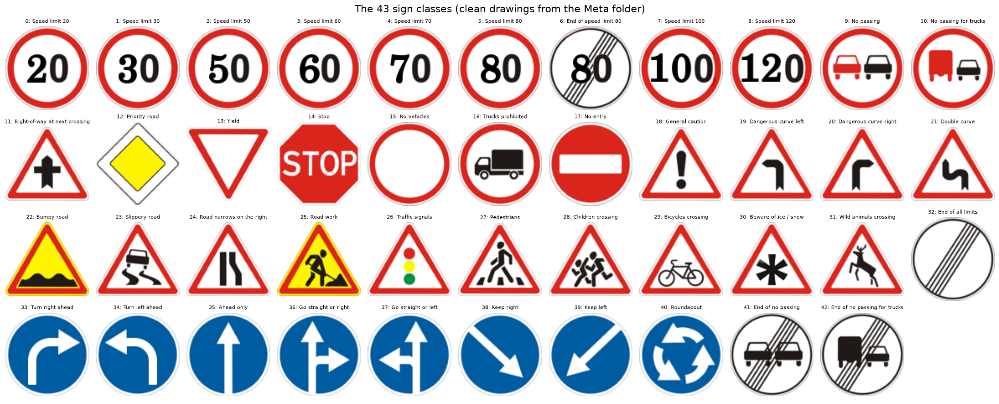

In [19]:
# the clean drawing of every sign (Meta folder)
fig, axes = plt.subplots(4, 11, figsize=(22, 9))
for ax in axes.ravel():
    ax.axis('off')
for ax, (_, r) in zip(axes.ravel(), meta.sort_values('ClassId').iterrows()):
    im = Image.open(os.path.join(DATA_DIR, r['Path'])).convert('RGBA')
    white = Image.new('RGBA', im.size, 'white')
    ax.imshow(Image.alpha_composite(white, im).convert('RGB'))
    ax.set_title(f"{r['ClassId']}: {SIGN_NAMES[r['ClassId']]}", fontsize=8)
plt.suptitle('The 43 sign classes (clean drawings from the Meta folder)', fontsize=16)
plt.tight_layout()
plt.show()

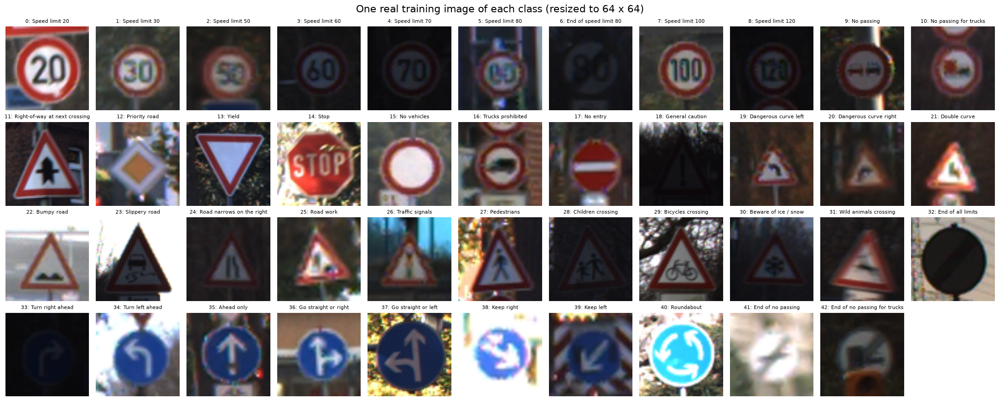

In [20]:
# one random real photo of every class
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(4, 11, figsize=(22, 9))
for ax in axes.ravel():
    ax.axis('off')
for ax, c in zip(axes.ravel(), range(43)):
    i = rng.choice(np.where((df['ClassId'] == c) & (df['Set'] == 'Train'))[0])
    ax.imshow(X[i])
    ax.set_title(f'{c}: {SIGN_NAMES[c]}', fontsize=8)
plt.suptitle('One real training image of each class (resized to 64 x 64)', fontsize=16)
plt.tight_layout()
plt.show()

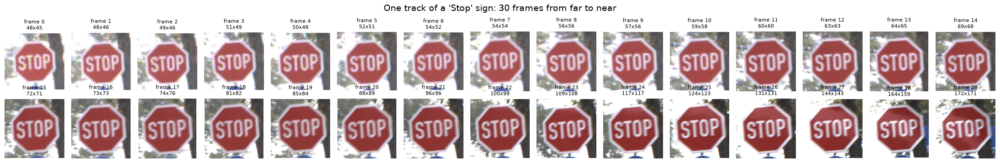

In [21]:
# one track: the same sign filmed 30 times while the car drives towards it (original sizes)
track = df[df['TRACK'] == df.loc[df['ClassId'] == 14, 'TRACK'].iloc[0]].sort_values('FRAME')
fig, axes = plt.subplots(2, 15, figsize=(22, 3.6))
for ax, (_, r) in zip(axes.ravel(), track.iterrows()):
    ax.imshow(Image.open(r['Path'])); ax.axis('off')
    ax.set_title(f"frame {int(r['FRAME'])}\n{r['Width']}x{r['Height']}", fontsize=8)
plt.suptitle(f"One track of a '{SIGN_NAMES[14]}' sign: 30 frames from far to near", fontsize=14)
plt.tight_layout()
plt.show()

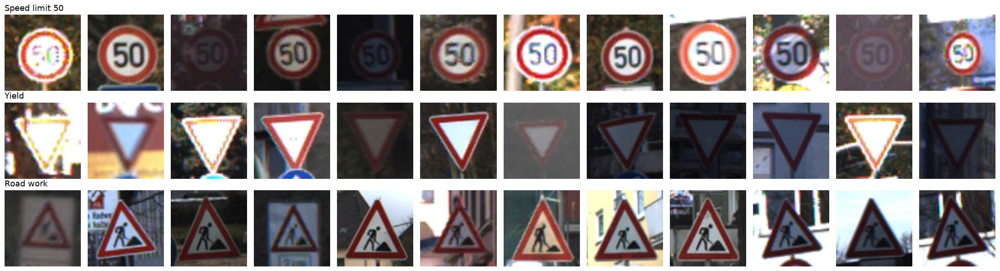

In [22]:
# 12 images of the same class: how different can one sign look?
fig, axes = plt.subplots(3, 12, figsize=(22, 6))
for row, c in zip(axes, [2, 13, 25]):
    for ax, i in zip(row, rng.choice(np.where(df['ClassId'] == c)[0], 12, replace=False)):
        ax.imshow(X[i]); ax.axis('off')
    row[0].set_title(SIGN_NAMES[c], loc='left', fontsize=13)
plt.tight_layout()
plt.show()

**Insights:**
- The **Meta drawings** are clean and perfect, but the **real images** are blurry, small and often dark. In the second grid, the digits of "End of speed limit 80", "Speed limit 120" and "Turn right ahead" are hard to read even for a person.
- **Many classes look almost the same:** the **9 speed-limit signs** are all red circles that differ only by their digits; the **15 red warning triangles** differ only by a small black picture in the middle; the **8 blue circles** differ only by the direction of the arrows. At 30-40 pixels these details are only a few pixels wide, so the model has to read very fine details.
- **Tracks:** the "Stop" track grows from **48 x 45 px (frame 0)** to **172 x 171 px (frame 29)**. Neighbouring frames are almost identical pictures. If one frame were in training and the next one in testing, the model would only need to remember the picture.
- **The same sign can look very different:** "Speed limit 50" goes from over-exposed white to almost black. The yield and road-work signs appear in sun, shade and with different backgrounds. Parts of **other signs** are often visible at the edges (a sign above or below on the same pole).

## 4. Histograms

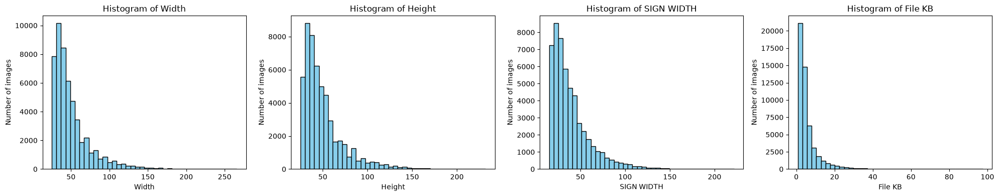

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, ['Width', 'Height', 'SIGN WIDTH', 'File KB']):
    ax.hist(df[col], bins=40, color='skyblue', edgecolor='black')
    ax.set_title(f'Histogram of {col}')
    ax.set_xlabel(col); ax.set_ylabel('Number of images')
plt.tight_layout()
plt.show()

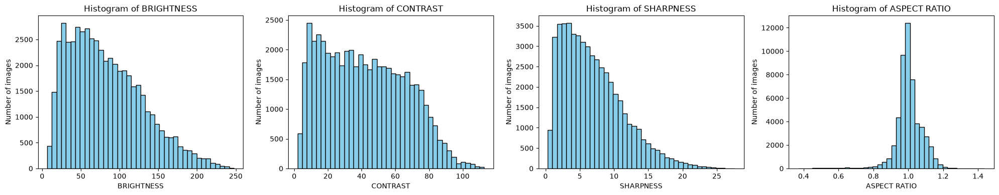

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, ['BRIGHTNESS', 'CONTRAST', 'SHARPNESS', 'ASPECT RATIO']):
    ax.hist(df[col], bins=40, color='skyblue', edgecolor='black')
    ax.set_title(f'Histogram of {col}')
    ax.set_xlabel(col); ax.set_ylabel('Number of images')
plt.tight_layout()
plt.show()

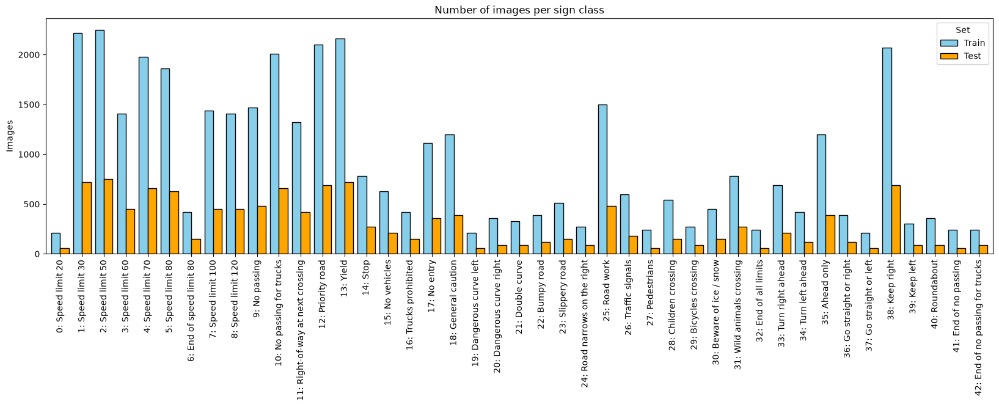

Train: smallest class 210 | largest class 2250 | ratio 10.7
Share of each class in Train and Test is almost the same, correlation: 0.9987


In [25]:
counts = df.groupby(['ClassId', 'Set']).size().unstack()[['Train', 'Test']]
counts.index = [f'{c}: {SIGN_NAMES[c]}' for c in counts.index]
counts.plot(kind='bar', figsize=(20, 5), color=['skyblue', 'orange'], edgecolor='black', width=0.8)
plt.title('Number of images per sign class')
plt.ylabel('Images')
plt.show()
print('Train: smallest class', counts['Train'].min(), '| largest class', counts['Train'].max(),
      '| ratio', round(counts['Train'].max() / counts['Train'].min(), 1))
print('Share of each class in Train and Test is almost the same, correlation:',
      round((counts['Train'] / counts['Train'].sum()).corr(counts['Test'] / counts['Test'].sum()), 4))

**Insights:**
- **Width and Height** are strongly **right-skewed**: the most common width is **31 px**, **43.6% of the images are 40 px wide or smaller**, and only **5% are wider than 100 px**. The sign itself (SIGN WIDTH) is 15 to 222 px. Most signs are seen from far away.
- **File size** has the same shape as the width (a bigger image makes a bigger file).
- **Brightness** is right-skewed with its peak in the dark area: most images were taken in **poor light**. Contrast is spread widely (2-113), sharpness is right-skewed (most images are a bit blurry). **Aspect ratio** is a narrow peak at 1.0: the images are square crops around the sign.
- **Images per class:** the most common signs (speed limits 30 and 50, yield, priority road, keep right) have 2,000-2,250 training images. The rarest (speed limit 20, dangerous curve left, go straight or left) have only 210. The test set has **the same class shares** (correlation 0.9987), so it reflects the same road situation.
- **Decision:** no rebalancing of the training data. Instead the **validation split is stratified by class**, and **macro F1** (every class counts the same) is reported next to accuracy, so we can see if the small classes are recognised as well as the large ones.

## 5. Relationship Plots (relplot)

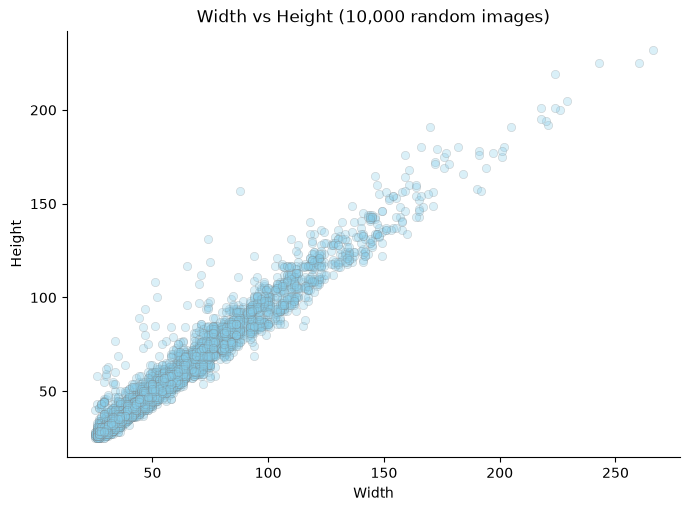

Correlation Width - Height: 0.98


In [26]:
sample = df.sample(10000, random_state=SEED)
sns.relplot(data=sample, x='Width', y='Height', alpha=0.3, color='skyblue', edgecolor='gray', height=5, aspect=1.4)
plt.title('Width vs Height (10,000 random images)')
plt.show()
print('Correlation Width - Height:', round(df['Width'].corr(df['Height']), 3))

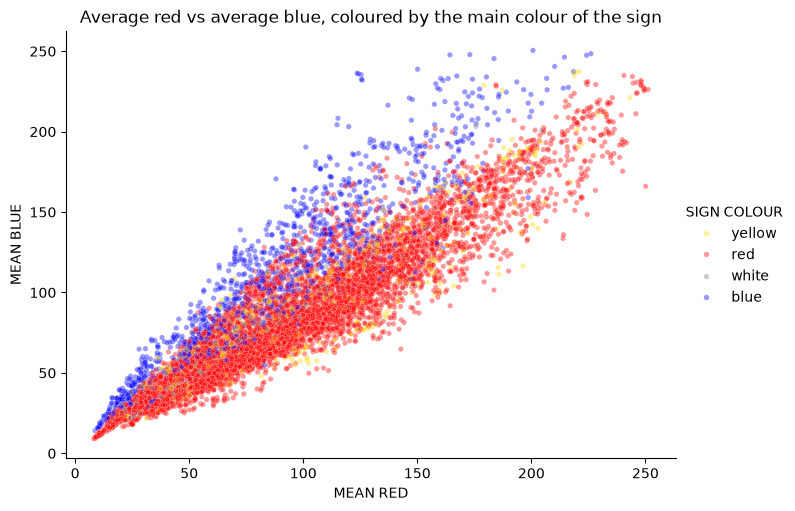

,MEAN RED,MEAN GREEN,MEAN BLUE,BRIGHTNESS
SIGN COLOUR,,,,
blue,86.199997,91.699997,106.800003,94.900002
red,86.800003,77.000000,77.599998,80.500000
white,62.200001,60.599998,60.900002,61.299999
yellow,96.099998,90.699997,88.000000,91.599998


In [27]:
sns.relplot(data=sample, x='MEAN RED', y='MEAN BLUE', hue='SIGN COLOUR', palette={'red': 'red', 'blue': 'blue', 'yellow': 'gold', 'white': 'gray'},
            alpha=0.4, s=15, height=5, aspect=1.4)
plt.title('Average red vs average blue, coloured by the main colour of the sign')
plt.show()
df.groupby('SIGN COLOUR')[['MEAN RED', 'MEAN GREEN', 'MEAN BLUE', 'BRIGHTNESS']].mean().round(1)

**Insights:**
- **Width vs Height** lies almost on one straight line (correlation **0.98**): every image is a nearly square crop around the sign, from about 25 px (far away) to over 200 px (very close).
- **Red vs Blue:** the **blue signs** (mandatory arrows) lie a bit above the red ones: their average blue is **106.8** against **77.6** for red signs, and they are a bit brighter (94.9 vs 80.5). But the clouds **overlap a lot**, because the average colour of the image is mostly decided by the **light and the background**, not by the sign. The **white signs** (the "end of ..." signs) are the darkest on average (61.3).

## 6. Pair Plot

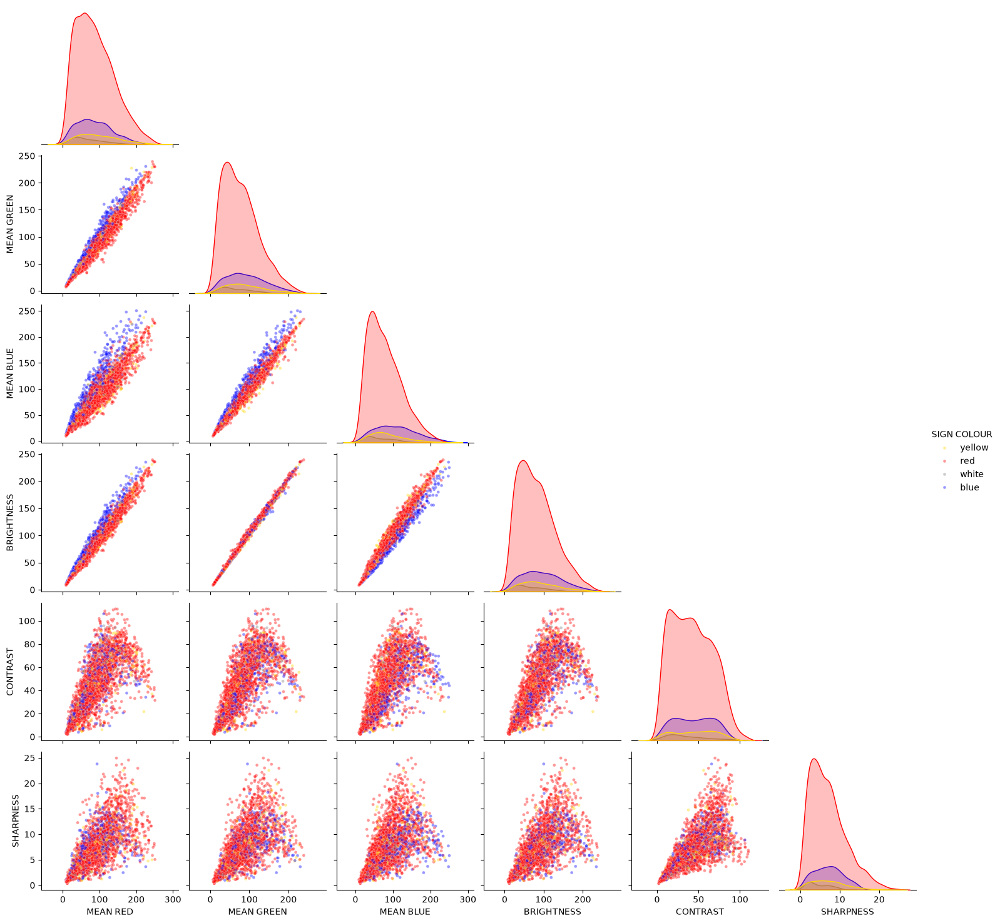

In [28]:
sns.pairplot(df.sample(3000, random_state=SEED)[['MEAN RED', 'MEAN GREEN', 'MEAN BLUE', 'BRIGHTNESS', 'CONTRAST', 'SHARPNESS', 'SIGN COLOUR']],
             hue='SIGN COLOUR', palette={'red': 'red', 'blue': 'blue', 'yellow': 'gold', 'white': 'gray'},
             plot_kws={'alpha': 0.4, 's': 12}, corner=True)
plt.show()

**Insights:**
- **MEAN RED, MEAN GREEN, MEAN BLUE and BRIGHTNESS lie almost on straight lines** (correlation 0.92-1.00): a bright image is bright in all three colours, so these four columns mostly measure **how much light** there was.
- The only visible separation is **blue signs vs red signs in the MEAN BLUE vs MEAN RED plot**: the blue points sit above the red cloud. Everything else overlaps.
- **CONTRAST and SHARPNESS increase with brightness**: dark images are also flat and blurry, so dark images are the hard ones.
- **Red signs dominate**: 40,140 images (**77.4%**) are red signs (red circles and triangles, stop, yield), 7,409 (14.3%) blue, 2,790 (5.4%) yellow (priority road) and 1,500 (2.9%) white.

## 7. Box Plots and Outliers (IQR method)

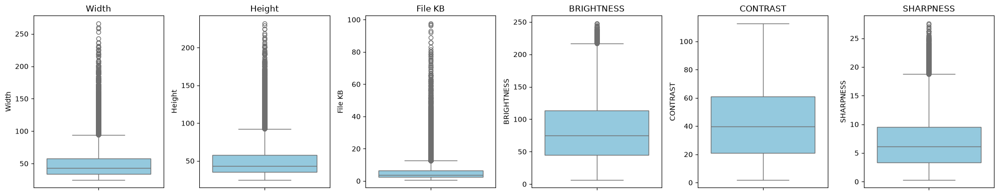

In [29]:
box_cols = ['Width', 'Height', 'File KB', 'BRIGHTNESS', 'CONTRAST', 'SHARPNESS']
fig, axes = plt.subplots(1, 6, figsize=(20, 4))
for ax, col in zip(axes, box_cols):
    sns.boxplot(y=df[col], ax=ax, color='skyblue')
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [30]:
outlier_rows = []
for col in box_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    low, high = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    outlier_rows.append([col, round(low, 1), round(high, 1), n_out, round(n_out / len(df) * 100, 2)])
pd.DataFrame(outlier_rows, columns=['Column', 'Lower limit', 'Upper limit', 'Outliers', 'Outliers %'])

,Column,Lower limit,Upper limit,Outliers,Outliers %
0,Width,-2.0,94.0,3370,6.50
1,Height,0.5,92.5,3367,6.50
2,File KB,-3.6,12.6,4845,9.35
3,BRIGHTNESS,-58.5,217.0,299,0.58
4,CONTRAST,-39.4,121.1,0,0.00
5,SHARPNESS,-5.9,18.8,842,1.62


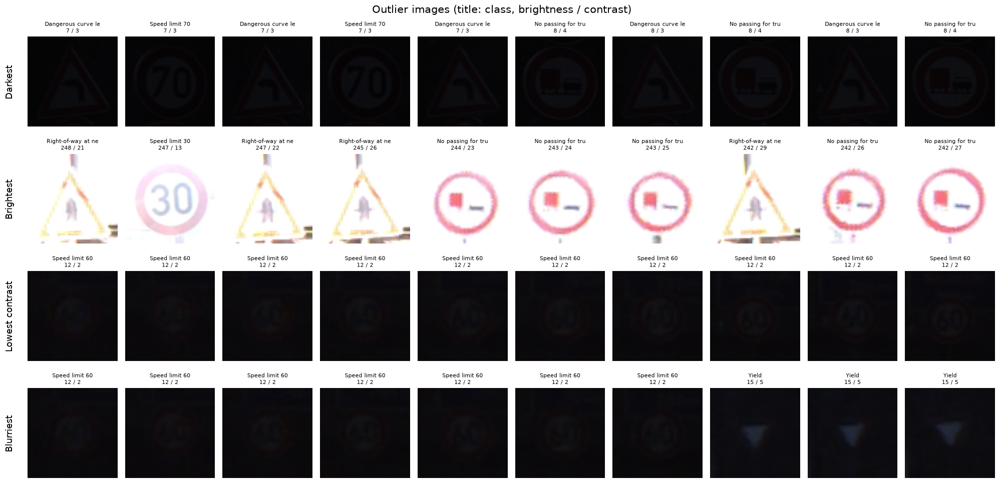

In [31]:
# what do the outliers look like? darkest, brightest, lowest-contrast and blurriest images
groups = {'Darkest': df.nsmallest(10, 'BRIGHTNESS').index,
          'Brightest': df.nlargest(10, 'BRIGHTNESS').index,
          'Lowest contrast': df.nsmallest(10, 'CONTRAST').index,
          'Blurriest': df.nsmallest(10, 'SHARPNESS').index}
fig, axes = plt.subplots(4, 10, figsize=(20, 10))
for row, (title, idx) in zip(axes, groups.items()):
    for ax, i in zip(row, idx):
        ax.imshow(X[i]); ax.axis('off')
        ax.set_title(f"{SIGN_NAMES[df['ClassId'].iat[i]][:18]}\n{df['BRIGHTNESS'].iat[i]:.0f} / {df['CONTRAST'].iat[i]:.0f}", fontsize=8)
    row[0].text(-10, 32, title, rotation=90, va='center', ha='right', fontsize=13)
plt.suptitle('Outlier images (title: class, brightness / contrast)', fontsize=15)
plt.tight_layout()
plt.show()

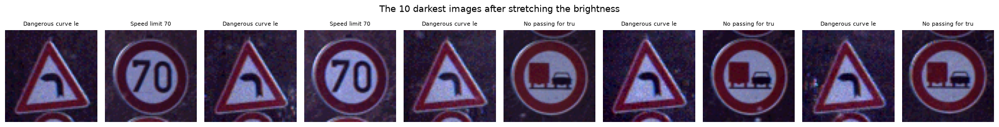

In [32]:
# the same darkest images made brighter (each image stretched to the full 0-255 range): is the sign still there?
fig, axes = plt.subplots(1, 10, figsize=(20, 2.6))
for ax, i in zip(axes, groups['Darkest']):
    img = X[i].astype(np.float32)
    ax.imshow(((img - img.min()) / (img.max() - img.min() + 1e-6) * 255).astype(np.uint8)); ax.axis('off')
    ax.set_title(SIGN_NAMES[df['ClassId'].iat[i]][:18], fontsize=8)
plt.suptitle('The 10 darkest images after stretching the brightness', fontsize=13)
plt.tight_layout()
plt.show()

**Outliers**
- **Width / Height:** 3,370 images (6.5%) are above 94 px. These are the **close-up frames at the end of a track**, the clearest images in the data, not errors. **Kept.**
- **File size:** 4,845 images (9.4%) are above 12.6 KB, the same large images (all are at least 59 px wide). **Kept.**
- **Brightness:** the lower IQR limit is below 0, so only the **299 very bright images** (above 217, 0.6%) are marked: signs in **direct sunlight**, with washed-out colours (yellow-looking triangles, pink rings). **Contrast:** no outliers. **Sharpness:** 842 very sharp images (1.6%), again the large close-ups.
- **The darkest images** (brightness 7-8, there are 85 images below 10) look completely black. But after stretching the brightness, **the sign is clearly there** (dangerous curve left, speed limit 70, no passing for trucks): the information is in the pixels, it is only squeezed into a few gray levels. The **lowest-contrast and blurriest** images are frames of one dark "Speed limit 60" track (brightness 12, contrast 2).
- **Decision:** all outliers are **kept**. A camera on a real car sees the same sun, night and distance. Instead of removing them, the training uses **brightness and contrast augmentation**. Part 3 checks whether dark images are really worse.

## 8. Line Plots
### Colour distribution of the pixels

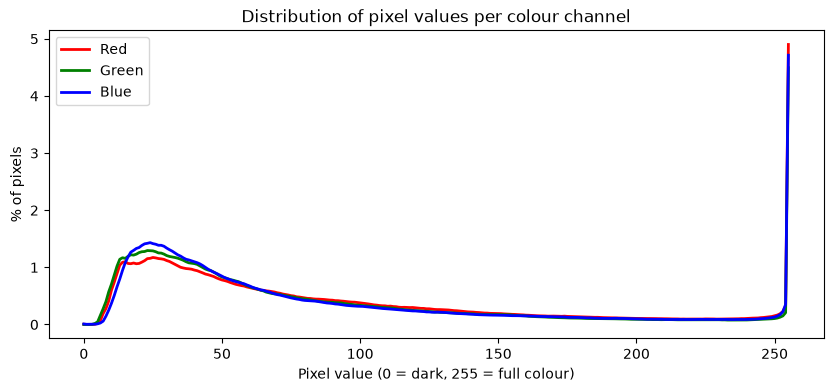

Average value -> red: 86.8, green: 79.4, blue: 81.6


In [33]:
# share of pixels at each intensity (0-255) for each colour channel, from 5,000 random images
pix = X[np.sort(rng.choice(len(df), 5000, replace=False))]
plt.figure(figsize=(10, 4))
for ch, (name, colour) in enumerate([('Red', 'red'), ('Green', 'green'), ('Blue', 'blue')]):
    hist = np.bincount(pix[..., ch].ravel(), minlength=256) / pix[..., ch].size * 100
    plt.plot(range(256), hist, color=colour, linewidth=2, label=name)
plt.title('Distribution of pixel values per colour channel')
plt.xlabel('Pixel value (0 = dark, 255 = full colour)'); plt.ylabel('% of pixels')
plt.legend()
plt.show()
print('Average value -> red: %.1f, green: %.1f, blue: %.1f' % tuple(pix.reshape(-1, 3).mean(axis=0)))

### How the image changes along a track (car driving towards the sign)

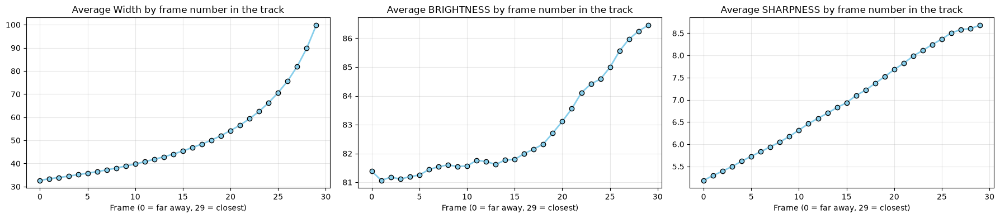

,Width,BRIGHTNESS,SHARPNESS
FRAME,,,
0.0,32.7,81.400002,5.2
10.0,39.8,81.599998,6.3
20.0,54.2,83.099998,7.7
29.0,99.8,86.500000,8.7


In [34]:
by_frame = df[df['Set'] == 'Train'].groupby('FRAME')[['Width', 'BRIGHTNESS', 'SHARPNESS']].mean()
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, by_frame.columns):
    ax.plot(by_frame.index, by_frame[col], marker='o', color='skyblue', markeredgecolor='black', linewidth=2)
    ax.set_title(f'Average {col} by frame number in the track'); ax.set_xlabel('Frame (0 = far away, 29 = closest)')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
by_frame.iloc[[0, 10, 20, 29]].round(1)

**Insights:**
- **Pixels:** all three colour channels are **highest at dark values (about 15-40)** and fall slowly towards bright values, with a **spike at 255** (about 5% of pixels): over-exposed sky and white sign backgrounds. The averages are almost equal (red 86.8, green 79.4, blue 81.6), so the images are **gray and dark overall**. The useful colour (the red ring, the blue disc) is only a small part of each image. Each channel is normalised before it goes into the CNN.
- **Along a track:** the average width grows from **32.7 px (frame 0)** to 39.8 px (frame 10), 54.2 px (frame 20) and **99.8 px (frame 29)**, about 3 times bigger. Sharpness rises from **5.2 to 8.7**, while brightness stays almost the same (81.4 to 86.5). So **the first frames of every track (sign far away) are the smallest and blurriest**, and these are the moments when a car would most like to know the sign early.

## 9. Bar Plots

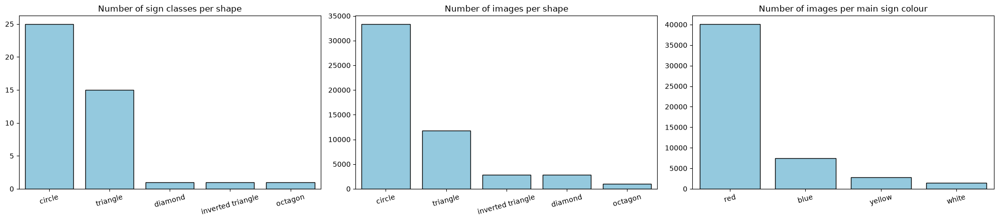

SIGN COLOUR,blue,red,white,yellow
SHAPE,,,,
circle,7409,24450,1500,0
diamond,0,0,0,2790
inverted triangle,0,2880,0,0
octagon,0,1050,0,0
triangle,0,11760,0,0


In [35]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
shape_cls = meta.assign(SHAPE=meta['ShapeId'].map(SHAPES)).groupby('SHAPE')['ClassId'].count().sort_values(ascending=False)
sns.barplot(x=shape_cls.index, y=shape_cls.values, color='skyblue', edgecolor='black', ax=axes[0])
axes[0].set_title('Number of sign classes per shape')
sh = df['SHAPE'].value_counts()
sns.barplot(x=sh.index, y=sh.values, color='skyblue', edgecolor='black', ax=axes[1])
axes[1].set_title('Number of images per shape')
co = df['SIGN COLOUR'].value_counts()
sns.barplot(x=co.index, y=co.values, color='skyblue', edgecolor='black', ax=axes[2])
axes[2].set_title('Number of images per main sign colour')
for ax in axes: ax.set_xlabel(''); ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()
pd.crosstab(df['SHAPE'], df['SIGN COLOUR'])

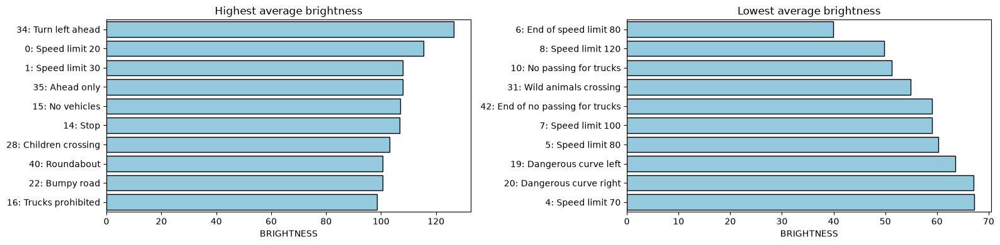

In [36]:
by_class = df.groupby('ClassId')[['BRIGHTNESS', 'CONTRAST', 'SHARPNESS', 'Width', 'MEAN RED', 'MEAN BLUE']].mean()
by_class.index = [f'{c}: {SIGN_NAMES[c]}' for c in by_class.index]

def class_bars(col, title, n=10):
    fig, axes = plt.subplots(1, 2, figsize=(16, 4))
    top = by_class[col].sort_values(ascending=False).head(n)
    bottom = by_class[col].sort_values().head(n)
    sns.barplot(x=top.values, y=top.index, color='skyblue', edgecolor='black', ax=axes[0])
    sns.barplot(x=bottom.values, y=bottom.index, color='skyblue', edgecolor='black', ax=axes[1])
    axes[0].set_title(f'Highest {title}'); axes[1].set_title(f'Lowest {title}')
    for ax in axes: ax.set_xlabel(col); ax.set_ylabel('')
    plt.tight_layout()
    plt.show()

class_bars('BRIGHTNESS', 'average brightness')

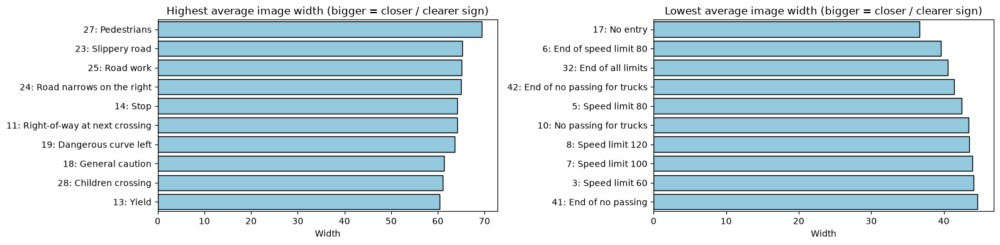

In [37]:
class_bars('Width', 'average image width (bigger = closer / clearer sign)')

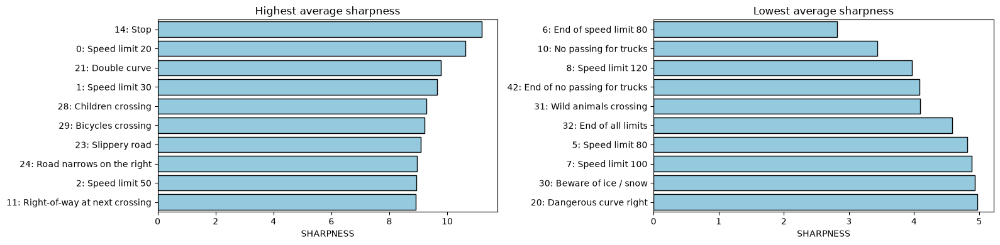

In [38]:
class_bars('SHARPNESS', 'average sharpness')

**Insights:**
- **Shapes:** 25 classes are circles, 15 are triangles, and **priority road (diamond), stop (octagon) and yield (inverted triangle) are the only classes with their shape**, so they should be easy. The **red circles** (13 classes, including all the speed limits) and the **red triangles** (15 classes) are the large look-alike groups and should be the hardest.
- **Brightness by class:** darkest **End of speed limit 80 (40.0), Speed limit 120 (49.8), No passing for trucks (51.3)**; brightest **Turn left ahead (126.4), Speed limit 20 (115.5), Speed limit 30 (108.0)**. These differences come mostly from **where and when** each sign was filmed, not from the sign: brightness varies by 41.6 points (standard deviation) **inside** a class.
- **Image width by class:** the triangles are the largest in the images (**Pedestrians 69.4 px, Slippery road 65.2, Road work 65.0**). The smallest are **No entry (36.6), End of speed limit 80 (39.6), End of all limits (40.6)**.
- **Sharpness:** lowest for **End of speed limit 80 (2.8), No passing for trucks (3.4), Speed limit 120 (4.0)**, which are also among the darkest classes. Highest for **Stop (11.2), Speed limit 20 (10.6), Double curve (9.8)**.

## 10. Label Encoding

In [39]:
from sklearn.preprocessing import LabelEncoder

# the target (ClassId) is already a number 0-42; the text columns SHAPE and SIGN COLOUR are encoded for the heat map
for col in ['SHAPE', 'SIGN COLOUR']:
    le = LabelEncoder()
    df[col + ' CODE'] = le.fit_transform(df[col])
    print(col, dict(zip(le.classes_, le.transform(le.classes_))))
class_names = [f'{c}: {n}' for c, n in enumerate(SIGN_NAMES)]
y_all = df['ClassId'].values

SHAPE {'circle': np.int64(0), 'diamond': np.int64(1), 'inverted triangle': np.int64(2), 'octagon': np.int64(3), 'triangle': np.int64(4)}
SIGN COLOUR {'blue': np.int64(0), 'red': np.int64(1), 'white': np.int64(2), 'yellow': np.int64(3)}


The target column **ClassId** is already a number from 0 to 42, so it does not need encoding: the model outputs one score for each number. The two text columns **SHAPE** and **SIGN COLOUR** are turned into numbers with LabelEncoder so they can be used in the heat map.

## 11. Heat Map and Feature Selection

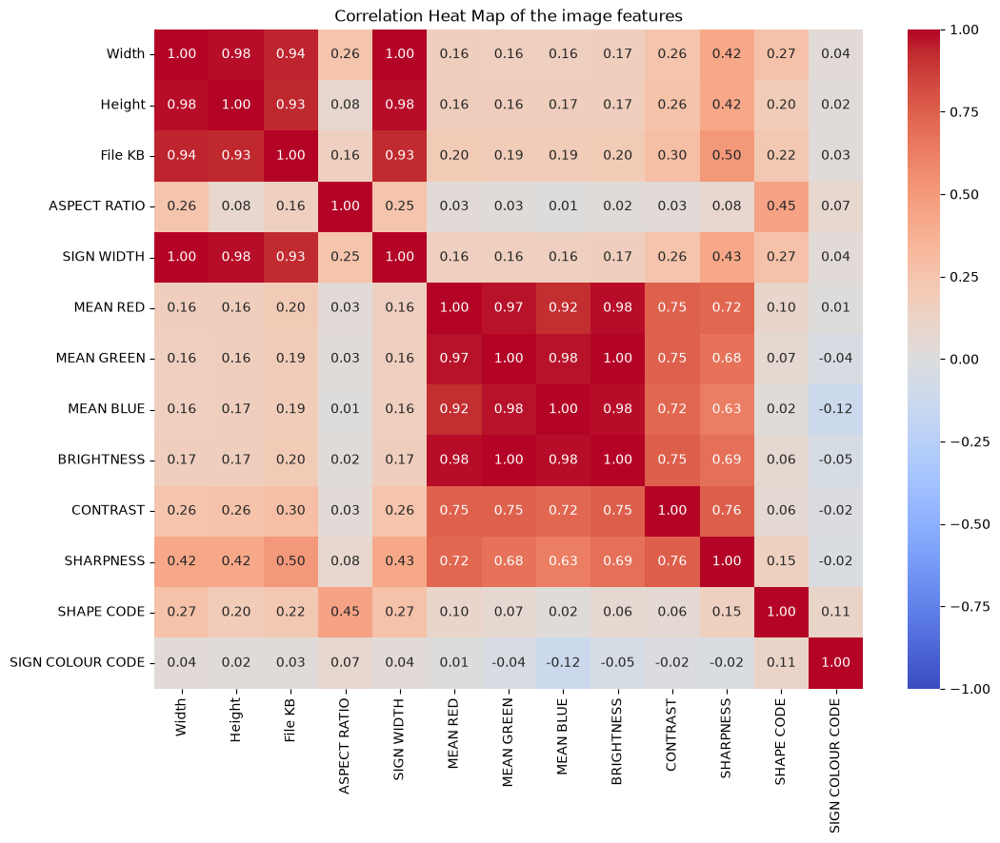

In [40]:
num = df[['Width', 'Height', 'File KB', 'ASPECT RATIO', 'SIGN WIDTH', 'MEAN RED', 'MEAN GREEN', 'MEAN BLUE',
          'BRIGHTNESS', 'CONTRAST', 'SHARPNESS', 'SHAPE CODE', 'SIGN COLOUR CODE']]
plt.figure(figsize=(12, 9))
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heat Map of the image features')
plt.show()

In [41]:
# how much does each simple feature change between classes? (share of variance explained by the class, eta squared)
eta = {}
for col in num.columns[:11]:
    total = ((df[col] - df[col].mean()) ** 2).sum()
    between = (df.groupby('ClassId')[col].transform('mean') - df[col].mean()).pow(2).sum()
    eta[col] = round(between / total * 100, 1)
pd.Series(eta, name='% of variation explained by the sign class').sort_values(ascending=False)

ASPECT RATIO    29.800000
SHARPNESS       19.200001
MEAN BLUE       17.500000
MEAN RED        16.500000
BRIGHTNESS      15.900000
MEAN GREEN      15.500000
SIGN WIDTH      10.800000
Width           10.500000
CONTRAST        10.400000
File KB          9.100000
Height           7.700000
Name: % of variation explained by the sign class, dtype: float64

**Feature selection**
- **Strong correlations:** the size columns (Width, Height, SIGN WIDTH, File KB) are correlated **0.93-1.00**, so they are really one feature (distance to the sign). The colour columns and BRIGHTNESS are correlated **0.92-1.00**, so they are one feature too (amount of light). CONTRAST and SHARPNESS go with brightness (0.63-0.76). SHAPE CODE is related only to ASPECT RATIO (0.45): triangle and diamond crops are a bit wider than tall.
- **Class effect:** the sign class explains **30% of the aspect ratio**, 19% of the sharpness, 15-18% of the colour columns and only **8-11% of the size columns**. **At least 70% of the differences between images have nothing to do with the type of sign.**
- **Feature selection for the CNN:** a CNN does not use these hand-made columns. It uses all the **pixels** and learns its own features. The real choices are:
  - **Input 64 x 64** for the custom CNN (bigger than the median image, so little is lost). The pretrained networks get **128 x 128** (upscaled), closer to the size they were trained with.
  - **Keep colour (RGB)**: red vs blue is the first clue to the type of sign.
  - **Use the whole image, including the border around the sign**, and not the ROI box: in a real car the box would come from a detector and would never be perfect, so the model should not depend on an exact crop.
  - **Normalise** each channel with the ImageNet mean and standard deviation.
- The simple columns are used once more, below, as **Model 0**, to prove that they are not enough.

# Part 2: Predictive Model

## Which algorithm suits this data best?
We want to put each image into **one of 43 sign classes**, so this is a **supervised multi-class image classification** problem.
- A **Convolutional Neural Network (CNN)** reads the raw pixels. Its first layers find edges and colours (the red ring, the blue disc), the middle layers find parts (arrows, digits, a car, a person) and the last layers recognise the whole sign. It learns these features by itself, which is why CNNs are the standard model for images.

**Models compared:**
1. **Custom CNN** built from scratch (4 convolution blocks) at 64 x 64 pixels. Traffic signs are simple, standard drawings, so a small CNN may be enough.
2. **MobileNetV3 as a fixed feature extractor** (transfer learning): a CNN already trained on 1.2 million ImageNet photos turns each sign image into 1,280 numbers, and only a final layer is trained (with a grid search on its settings).
3. **MobileNetV3 fine-tuned**: the whole pretrained network is trained a bit more on traffic signs. Small and fast, made for mobile devices.
4. **EfficientNet-B0 fine-tuned**: a modern CNN designed to give high accuracy for little computing power.

Then **test-time augmentation** and two ensembles (**soft voting** and **stacking**).

**Metrics:** **Accuracy** = the prediction is right. **Macro F1** = F1 score averaged over the 43 classes, so the small classes (210 training images) count as much as the big ones (2,250). **Top-3 accuracy** = the right sign is in the 3 best guesses.

## Train / Validation / Test Split
- **Test:** the official **`Test.csv`** images (12,630), kept apart until the end. They come from different tracks than the training images.
- **Validation:** about **10% of the training tracks** of every class, and at least one track per class (the smallest classes have only 7 tracks). The split is done by **track, not by image**: the 30 frames of one track are almost the same picture, so if some frames were in training and others in validation, the validation score would be far too optimistic (the model would only need to remember the sign it already saw). This is checked below with the Random Forest.

In [42]:
train_all = np.where(df['Set'] == 'Train')[0]
test_idx = np.where(df['Set'] == 'Test')[0]
# validation = about 10% of the tracks of every class (at least 1 track per class), so all 43 classes are in it
tracks = df.loc[train_all].groupby('TRACK')['ClassId'].first()
val_tracks = []
for c, t in tracks.groupby(tracks):
    val_tracks += list(t.sample(max(1, round(len(t) * 0.1)), random_state=SEED).index)
is_val = df['TRACK'].isin(val_tracks).values
train_idx, val_idx = train_all[~is_val[train_all]], train_all[is_val[train_all]]
print('Train:', len(train_idx), '| Validation:', len(val_idx), '| Test:', len(test_idx))
print('Tracks in both train and validation:', len(set(df['TRACK'].values[train_idx]) & set(df['TRACK'].values[val_idx])))
print('Classes in validation:', len(np.unique(y_all[val_idx])))

Train: 35219 | Validation: 3990 | Test: 12630
Tracks in both train and validation: 0
Classes in validation: 43


### Model 0: Random Forest on the simple image features (why we need a CNN, and why we split by track)
First a **5-fold cross-validation** of a Random Forest on the training images, done in two ways: with a **random split** (frames of the same track end up on both sides) and with a **group split by track** (GroupKFold). Then the Random Forest is tested on the official test set.

In [43]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import KFold, GroupKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score

simple_cols = ['Width', 'Height', 'File KB', 'ASPECT RATIO', 'SIGN WIDTH', 'MEAN RED', 'MEAN GREEN', 'MEAN BLUE',
               'BRIGHTNESS', 'CONTRAST', 'SHARPNESS']
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED)
Xs, ys, gs = df.loc[train_all, simple_cols], y_all[train_all], df['TRACK'].values[train_all]
cv_random = cross_val_score(rf, Xs, ys, cv=KFold(5, shuffle=True, random_state=SEED))
cv_group = cross_val_score(rf, Xs, ys, cv=GroupKFold(5), groups=gs)
print('5-fold CV accuracy, random split    :', cv_random.round(3), '-> mean', round(cv_random.mean(), 3))
print('5-fold CV accuracy, split by track  :', cv_group.round(3), '-> mean', round(cv_group.mean(), 3))

5-fold CV accuracy, random split    : [0.693 0.69  0.692 0.689 0.699] -> mean 0.692
5-fold CV accuracy, split by track  : [0.138 0.158 0.147 0.18  0.16 ] -> mean 0.157


In [44]:
rf.fit(df.loc[train_idx, simple_cols], y_all[train_idx])
rf_probs = rf.predict_proba(df.loc[test_idx, simple_cols])

def scores(y_true, probs):
    pred = probs.argmax(1)
    return {'Test Accuracy': accuracy_score(y_true, pred),
            'Macro F1': f1_score(y_true, pred, average='macro'),
            'Top-3 Accuracy': top_k_accuracy_score(y_true, probs, k=3, labels=range(43))}

y_test, y_val = y_all[test_idx], y_all[val_idx]
print('Random Forest on the test set:', {k: round(v, 4) for k, v in scores(y_test, rf_probs).items()})
print('Always predicting the largest class would give an accuracy of', round((y_test == np.bincount(y_all[train_idx]).argmax()).mean(), 4))

Random Forest on the test set: {'Test Accuracy': 0.1644, 'Macro F1': 0.1156, 'Top-3 Accuracy': 0.3497}
Always predicting the largest class would give an accuracy of 0.057


**Result:**
- **Cross-validation shows the leakage problem very clearly:** the same Random Forest on the same data gets **69.2% with a random 5-fold split** but only **15.7% when the folds are split by track** (GroupKFold). With the random split, frames of the same track are in training and testing, so the model recognises **the track** (same size, same light, same background), not the sign. That 69.2% is fake. **Every model in this notebook is therefore validated on tracks it has never seen**, and tested on the official test set.
- On the test set the Random Forest gets **16.4% accuracy** (macro F1 0.116, top-3 35.0%). That is 3 times better than always guessing the largest class (5.7%), but useless for a car. **We need a model that looks at the shapes, digits and pictograms inside the image: a CNN.**

### Data pipeline for the CNNs
- All 51,839 images (64 x 64) fit in the GPU memory (600 MB), so batches of 128 images are taken directly from the GPU, with no reading from disk.
- **Data augmentation (training only), done on the GPU:** each image is randomly **rotated** (up to 12 degrees), **zoomed** (85-115%), **shifted** (up to 10%) and made **brighter / darker** and **more / less contrasted**. The model never sees exactly the same picture twice, which reduces **overfitting**.
- **No left-right flip**, unlike for normal photos: a flipped "Turn left ahead" is a "Turn right ahead", and flipped digits are not digits. This is a choice made specifically for traffic signs.
- Pixels are **normalised** with the ImageNet mean and standard deviation, as the pretrained networks expect. The pretrained networks get the images resized to **128 x 128**.

In [45]:
BATCH_SIZE = 128
X_gpu = torch.from_numpy(X).to(device)              # uint8, N x 64 x 64 x 3
y_gpu = torch.from_numpy(y_all.astype(np.int64)).to(device)
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1) * 255
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1) * 255

def affine(x, angle, scale, tx, ty):
    """rotate (radians), zoom (scale > 1 = zoom in) and shift (fraction of the image) a batch of images"""
    cos, sin = torch.cos(angle) / scale, torch.sin(angle) / scale
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, mode='bilinear', padding_mode='border', align_corners=False)

def augment(x):
    n = len(x)
    u = lambda a, b: torch.empty(n, device=device).uniform_(a, b)
    x = affine(x, u(-12, 12) * np.pi / 180, u(0.85, 1.15), u(-0.1, 0.1), u(-0.1, 0.1))
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - mean) * u(0.7, 1.3).view(-1, 1, 1, 1) + mean        # contrast
    x = x * u(0.6, 1.4).view(-1, 1, 1, 1)                         # brightness
    return x.clamp(0, 255)

def to_input(ix, size, train=False, view=None):
    x = X_gpu[ix].permute(0, 3, 1, 2).float()
    if train:
        x = augment(x)
    elif view is not None:   # fixed zoom for test-time augmentation
        n = len(x); z = torch.zeros(n, device=device)
        x = affine(x, z, torch.full((n,), view, device=device), z, z)
    x = (x - MEAN) / STD
    if size != x.shape[-1]:
        x = F.interpolate(x, size=(size, size), mode='bilinear', align_corners=False)
    return x.contiguous(memory_format=torch.channels_last)

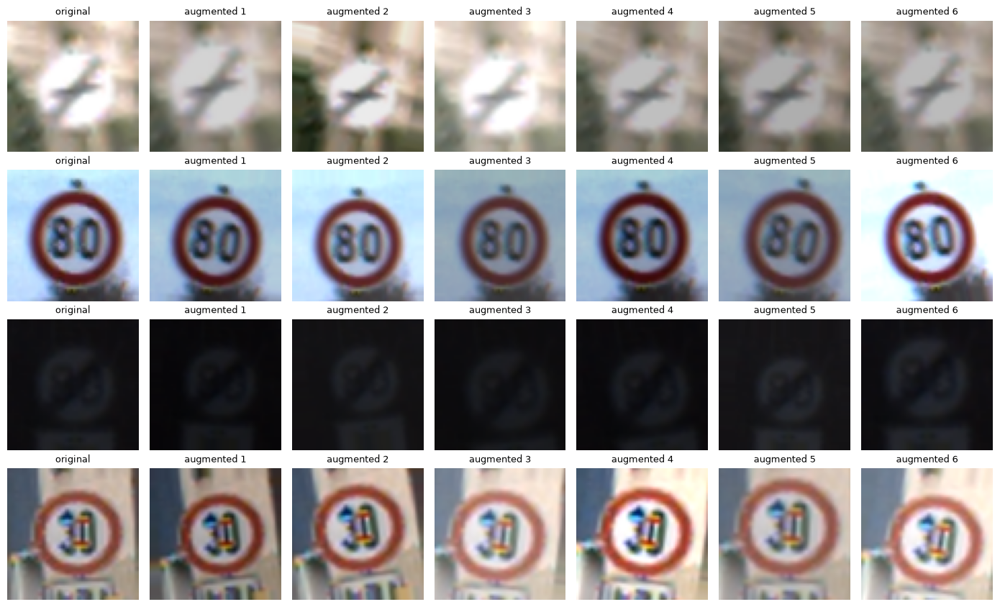

In [46]:
# check: what the model sees after augmentation (4 images, 6 random versions each)
demo = train_idx[rng.choice(len(train_idx), 4, replace=False)]
fig, axes = plt.subplots(4, 7, figsize=(14, 8.5))
for r, i in enumerate(demo):
    axes[r, 0].imshow(X[i]); axes[r, 0].set_title('original', fontsize=9)
    aug = augment(X_gpu[[i] * 6].permute(0, 3, 1, 2).float()).permute(0, 2, 3, 1).byte().cpu().numpy()
    for c in range(6):
        axes[r, c + 1].imshow(aug[c]); axes[r, c + 1].set_title(f'augmented {c + 1}', fontsize=9)
for ax in axes.ravel(): ax.axis('off')
plt.tight_layout()
plt.show()

### Training and evaluation functions
- **Loss:** cross-entropy with **label smoothing 0.1** (the model is taught to be 90% sure instead of 100% sure, which makes it less over-confident).
- **Optimizer:** AdamW (Adam with weight decay to keep the weights small).
- **Learning rate:** "one-cycle" schedule: it warms up in the first 15% of training and then slowly goes down to almost zero.
- **Mixed precision (bfloat16)** on the GPU to train faster.
- After every epoch the model is checked on the validation set. The trained model is saved, so the notebook can be run again without training again.

In [47]:
def file_name(name):
    return os.path.join(MODEL_DIR, name.lower().replace(' ', '_').replace('(', '').replace(')', '').replace('-', ''))

speed = {}
def log(msg):   # progress also written to a file, to follow long training runs
    with open(os.path.join(CACHE_DIR, 'training_log.txt'), 'a') as fh:
        fh.write(time.strftime('%H:%M:%S ') + msg + '\n')
TTA_VIEWS = [1.0, 1.1, 0.9]    # original, zoomed in 10%, zoomed out 10%

@torch.no_grad()
def predict_probs(model, ix, size, tta=False, name=None):
    """Probabilities for the images in ix (in the same order). tta=True averages 3 zoom levels of each image."""
    model.eval()
    out = []
    if device == 'xpu': torch.xpu.synchronize()
    t0 = time.time()
    for i in range(0, len(ix), 256):
        b = torch.as_tensor(ix[i:i + 256], device=device)
        with torch.autocast(device_type=device, dtype=torch.bfloat16):
            views = TTA_VIEWS if tta else [None]
            p = sum(model(to_input(b, size, view=v)).float().softmax(1) for v in views) / len(views)
        out.append(p)
    probs = torch.cat(out).cpu().numpy()
    if name:
        speed[name] = round(len(ix) / (time.time() - t0))
    return probs

def train_model(name, model, epochs, lr, size, wd=0.05):
    f = file_name(name)
    model = model.to(device).to(memory_format=torch.channels_last)
    if os.path.exists(f + '.pt'):
        model.load_state_dict(torch.load(f + '.pt', map_location=device))
        history = pd.read_csv(f + '_history.csv')
        print(f'{name}: loaded the model trained earlier')
        display(history)
        return model, history
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    steps = int(np.ceil(len(train_idx) / BATCH_SIZE))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * steps, pct_start=0.15)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    train_gpu = torch.as_tensor(train_idx, device=device)
    rows = []
    for epoch in range(1, epochs + 1):
        model.train()
        t0 = time.time()
        loss_sum = torch.zeros((), device=device); correct = torch.zeros((), device=device)
        order = train_gpu[torch.randperm(len(train_gpu), device=device)]
        for s in range(steps):
            b = order[s * BATCH_SIZE:(s + 1) * BATCH_SIZE]
            x, y = to_input(b, size, train=True), y_gpu[b]
            with torch.autocast(device_type=device, dtype=torch.bfloat16):
                out = model(x)
            loss = criterion(out.float(), y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step(); sched.step()
            loss_sum += loss.detach() * len(y); correct += (out.argmax(1) == y).sum()
        n = len(train_idx)
        val_probs = predict_probs(model, val_idx, size)
        val_loss = -np.log(val_probs[np.arange(len(val_idx)), y_val] + 1e-9).mean()
        rows.append([epoch, round(loss_sum.item() / n, 4), round(correct.item() / n, 4), round(val_loss, 4),
                     round((val_probs.argmax(1) == y_val).mean(), 4), round((time.time() - t0) / 60, 2)])
        print(f'{name} | epoch {epoch}/{epochs} | train loss {rows[-1][1]:.3f} | train acc {rows[-1][2]:.3f} | '
              f'val loss {rows[-1][3]:.3f} | val acc {rows[-1][4]:.4f} | {rows[-1][5]:.1f} min', flush=True)
        log(f'{name} epoch {epoch} val acc {rows[-1][4]:.4f} {rows[-1][5]:.1f} min')
    history = pd.DataFrame(rows, columns=['Epoch', 'Train Loss', 'Train Acc', 'Val Loss', 'Val Acc', 'Minutes'])
    torch.save(model.state_dict(), f + '.pt')
    history.to_csv(f + '_history.csv', index=False)
    return model, history

results = []
def add_result(name, approach, probs, history=None, model=None, size=None):
    row = {'Model': name, 'Approach': approach, 'Input size': size}
    row.update({k: round(v, 4) for k, v in scores(y_test, probs).items()})
    row['Test errors'] = int((probs.argmax(1) != y_test).sum())
    if model is not None:
        row['Parameters (M)'] = round(sum(p.numel() for p in model.parameters()) / 1e6, 2)
    if history is not None:
        row['Epochs'] = len(history); row['Train minutes'] = round(history['Minutes'].sum(), 1)
        row['Val Accuracy'] = history['Val Acc'].iloc[-1]
    row['Images / second (test)'] = speed.get(name)
    results.append(row)
    return pd.DataFrame([row])

add_result('Random Forest (simple features)', 'Colour, size, contrast, sharpness columns', rf_probs)

,Model,Approach,Input size,Test Accuracy,Macro F1,Top-3 Accuracy,Test errors,Images / second (test)
0,Random Forest (simple features),"Colour, size, contrast, sharpness columns",None,0.1644,0.1156,0.3497,10554,None


In [48]:
# number of training rounds (epochs) per model
EPOCHS = {'Custom CNN': 15, 'MobileNetV3 (fine-tuned)': 8, 'EfficientNet-B0 (fine-tuned)': 8}

### Model 1: Custom CNN
Four blocks of **[convolution 3x3 -> batch normalisation -> ReLU] x 2 -> max pooling**. The number of filters grows 32 -> 64 -> 128 -> 256 while the image shrinks from 64 x 64 to 4 x 4, then **global average pooling**, **dropout 30%** and the output layer with 43 classes.

In [49]:
class CustomCNN(nn.Module):
    def __init__(self, n_classes=43):
        super().__init__()
        def block(c_in, c_out):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
                nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
                nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

name = 'Custom CNN'
torch.manual_seed(SEED)
cnn, cnn_hist = train_model(name, CustomCNN(), EPOCHS[name], lr=3e-3, size=64)
cnn_probs = predict_probs(cnn, test_idx, size=64, name=name)
add_result(name, 'Trained from scratch', cnn_probs, cnn_hist, cnn, size=64)

Custom CNN: loaded the model trained earlier


,Epoch,Train Loss,Train Acc,Val Loss,Val Acc,Minutes
0,1,2.3331,0.4580,0.8020,0.8040,0.52
1,2,0.9005,0.9684,0.2918,0.9817,0.32
2,3,0.7783,0.9943,0.1631,0.9935,0.33
3,4,0.7465,0.9970,0.1832,0.9885,0.32
4,5,0.7315,0.9986,0.1529,0.9960,0.33
5,6,0.7243,0.9985,0.1235,0.9967,0.32
6,7,0.7165,0.9994,0.1270,0.9952,0.33
7,8,0.7112,0.9996,0.1353,0.9937,0.33
8,9,0.7078,0.9997,0.1256,0.9952,0.33
9,10,0.7066,0.9997,0.1367,0.9877,0.32


,Model,Approach,Input size,Test Accuracy,Macro F1,Top-3 Accuracy,Test errors,Parameters (M),Epochs,Train minutes,Val Accuracy,Images / second (test)
0,Custom CNN,Trained from scratch,64,0.9983,0.9977,0.9998,22,1.18,15,5.1,0.994,2676


**Custom CNN result: 99.83% test accuracy, macro F1 0.998, only 22 wrong images out of 12,630** (5.1 minutes of training for 15 epochs, 1.18 million parameters).
- Validation accuracy: **80.4% after epoch 1, 98.2% after epoch 2, 99.35% after epoch 3**, then between 98.8% and 99.7% for the rest of the training (99.4% at the end).
- The training accuracy on augmented images reaches 100%, while the validation loss stays flat around 0.12 from epoch 6, and the test result is excellent. There is a small gap, but it is **not harmful overfitting**. (The training loss cannot go below about 0.70 because of the label smoothing.)
- Traffic signs are **standard drawings**: every "Stop" sign is printed the same way. So even a small network trained from scratch on 35,219 images learns them almost perfectly, unlike food photos.

### Model 2: MobileNetV3 as a fixed feature extractor + Grid Search
The pretrained MobileNetV3-Large is **frozen** (not changed). Each image goes through it once and comes out as **1,280 numbers** (features). Then only a final **linear layer** (like a logistic regression) is trained on these numbers.

**Grid search:** we try every combination of **learning rate** and **weight decay** for this last layer and keep the one with the best validation accuracy.

In [50]:
weights = torchvision.models.MobileNet_V3_Large_Weights.IMAGENET1K_V2
extractor = torchvision.models.mobilenet_v3_large(weights=weights)
extractor.classifier = extractor.classifier[:2]          # keep the 960 -> 1280 layer, drop the ImageNet output layer
extractor = extractor.to(device).to(memory_format=torch.channels_last).eval()

def features(ix, tag):
    f = file_name(f'mobilenet_features_{tag}') + '.npy'
    if os.path.exists(f):
        return np.load(f)
    out = []
    with torch.no_grad():
        for i in range(0, len(ix), 256):
            with torch.autocast(device_type=device, dtype=torch.bfloat16):
                out.append(extractor(to_input(torch.as_tensor(ix[i:i + 256], device=device), 128)).float().cpu())
    out = torch.cat(out).numpy()
    np.save(f, out)
    return out

t0 = time.time()
F_train, F_val, F_test = features(train_idx, 'train'), features(val_idx, 'val'), features(test_idx, 'test')
y_train = y_all[train_idx]
print('Feature shapes:', F_train.shape, F_val.shape, F_test.shape, f'| {(time.time() - t0) / 60:.1f} min')

Feature shapes: (35219, 1280) (3990, 1280) (12630, 1280) | 0.0 min


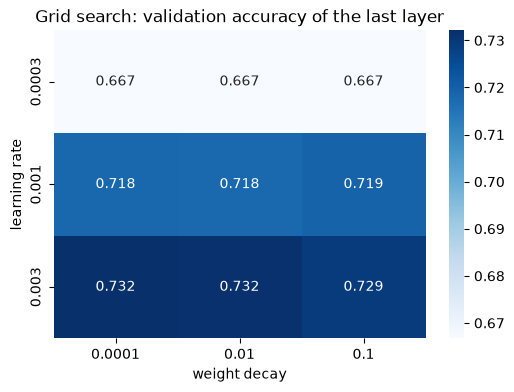

Best setting: {'learning rate': np.float64(0.003), 'weight decay': np.float64(0.0001), 'Val Accuracy': np.float64(0.7321)}


In [51]:
def train_head(F_tr, y_tr, lr, wd, epochs=15, bs=512):
    torch.manual_seed(SEED)
    head = nn.Linear(F_tr.shape[1], 43).to(device)
    opt = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=wd)
    Xt, yt = torch.tensor(F_tr, device=device), torch.tensor(y_tr, device=device)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * int(np.ceil(len(yt) / bs)))
    for _ in range(epochs):
        perm = torch.randperm(len(yt), device=device)
        for i in range(0, len(yt), bs):
            j = perm[i:i + bs]
            loss = F.cross_entropy(head(F.dropout(Xt[j], 0.2)), yt[j], label_smoothing=0.1)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return head

def head_probs(head, F_):
    with torch.no_grad():
        return head(torch.tensor(F_, device=device)).softmax(1).cpu().numpy()

grid = []
for lr in [3e-4, 1e-3, 3e-3]:
    for wd in [1e-4, 1e-2, 1e-1]:
        head = train_head(F_train, y_train, lr, wd)
        log(f'grid search lr={lr} wd={wd}')
        grid.append({'learning rate': lr, 'weight decay': wd, 'Val Accuracy': round((head_probs(head, F_val).argmax(1) == y_val).mean(), 4)})
grid = pd.DataFrame(grid)
plt.figure(figsize=(6, 4))
sns.heatmap(grid.pivot(index='learning rate', columns='weight decay', values='Val Accuracy'), annot=True, fmt='.3f', cmap='Blues')
plt.title('Grid search: validation accuracy of the last layer')
plt.show()
best = grid.sort_values('Val Accuracy', ascending=False).iloc[0]
print('Best setting:', dict(best))

In [52]:
name = 'MobileNetV3 (feature extractor)'
head = train_head(F_train, y_train, best['learning rate'], best['weight decay'])
fe_probs = head_probs(head, F_test)
add_result(name, 'Transfer learning, frozen CNN + grid search on last layer', fe_probs, size=128)

,Model,Approach,Input size,Test Accuracy,Macro F1,Top-3 Accuracy,Test errors,Images / second (test)
0,MobileNetV3 (feature extractor),"Transfer learning, frozen CNN + grid search on...",128,0.7333,0.6535,0.907,3368,None


**Grid search result (validation accuracy):**

| learning rate \ weight decay | 0.0001 | 0.01 | 0.1 |
|---|---|---|---|
| 0.0003 | 0.667 | 0.667 | 0.667 |
| 0.001 | 0.718 | 0.718 | 0.719 |
| **0.003** | **0.732** | 0.732 | 0.729 |

- The **learning rate matters** (66.7% -> 73.2%), **weight decay makes almost no difference**. Best setting: learning rate 0.003, weight decay 0.0001.
- **Feature extractor result: 73.3% test accuracy, macro F1 0.654, top-3 90.7%.** That is **far below the custom CNN (99.8%)**, the opposite of the Food project, where the frozen network beat the custom CNN. The ImageNet features describe objects in normal photos (dogs, cars, cups). They cannot tell the digits "60" from "80" on a blurry 64 px image blown up to 128 px. The macro F1 (0.654) is much lower than the accuracy, so the **small classes suffer the most**.
- The frozen network clearly has to adapt to traffic signs, so the next step is to **fine-tune** all of its layers.

### Model 3: MobileNetV3-Large fine-tuned
Now **all layers** of the pretrained MobileNetV3 are trained on the traffic signs, with a new output layer for 43 classes.

In [53]:
name = 'MobileNetV3 (fine-tuned)'
torch.manual_seed(SEED)
m = torchvision.models.mobilenet_v3_large(weights=torchvision.models.MobileNet_V3_Large_Weights.IMAGENET1K_V2)
m.classifier[3] = nn.Linear(1280, 43)
mobilenet, mobilenet_hist = train_model(name, m, EPOCHS[name], lr=1e-3, size=128)
mobilenet_probs = predict_probs(mobilenet, test_idx, size=128, name=name)
add_result(name, 'Transfer learning, fine-tuned', mobilenet_probs, mobilenet_hist, mobilenet, size=128)

MobileNetV3 (fine-tuned): loaded the model trained earlier


,Epoch,Train Loss,Train Acc,Val Loss,Val Acc,Minutes
0,1,1.5410,0.7427,0.2665,0.9481,1.78
1,2,0.7321,0.9912,0.2140,0.9684,0.98
2,3,0.7073,0.9966,0.1500,0.9877,1.09
3,4,0.6986,0.9982,0.1223,0.9930,1.03
4,5,0.6951,0.9986,0.1189,0.9960,1.05
5,6,0.6905,0.9995,0.1181,0.9947,0.98
6,7,0.6892,0.9997,0.1132,0.9972,0.93
7,8,0.6890,0.9998,0.1130,0.9975,1.03


,Model,Approach,Input size,Test Accuracy,Macro F1,Top-3 Accuracy,Test errors,Parameters (M),Epochs,Train minutes,Val Accuracy,Images / second (test)
0,MobileNetV3 (fine-tuned),"Transfer learning, fine-tuned",128,0.9918,0.9853,0.9987,104,4.26,8,8.9,0.9975,1871


### Model 4: EfficientNet-B0 fine-tuned

In [54]:
name = 'EfficientNet-B0 (fine-tuned)'
torch.manual_seed(SEED)
m = torchvision.models.efficientnet_b0(weights=torchvision.models.EfficientNet_B0_Weights.IMAGENET1K_V1)
m.classifier[1] = nn.Linear(1280, 43)
effnet, effnet_hist = train_model(name, m, EPOCHS[name], lr=1e-3, size=128)
effnet_probs = predict_probs(effnet, test_idx, size=128, name=name)
add_result(name, 'Transfer learning, fine-tuned', effnet_probs, effnet_hist, effnet, size=128)

EfficientNet-B0 (fine-tuned): loaded the model trained earlier


,Epoch,Train Loss,Train Acc,Val Loss,Val Acc,Minutes
0,1,1.6779,0.7150,0.1933,0.9662,2.11
1,2,0.7411,0.9893,0.1417,0.9867,1.59
2,3,0.7108,0.9960,0.1234,0.9932,1.60
3,4,0.7008,0.9979,0.1333,0.9895,1.56
4,5,0.6970,0.9986,0.1340,0.9915,1.53
5,6,0.6927,0.9995,0.1226,0.9940,1.63
6,7,0.6910,0.9997,0.1202,0.9947,1.66
7,8,0.6906,0.9998,0.1268,0.9930,1.69


,Model,Approach,Input size,Test Accuracy,Macro F1,Top-3 Accuracy,Test errors,Parameters (M),Epochs,Train minutes,Val Accuracy,Images / second (test)
0,EfficientNet-B0 (fine-tuned),"Transfer learning, fine-tuned",128,0.996,0.9953,0.9995,50,4.06,8,13.4,0.993,1388


### Learning curves

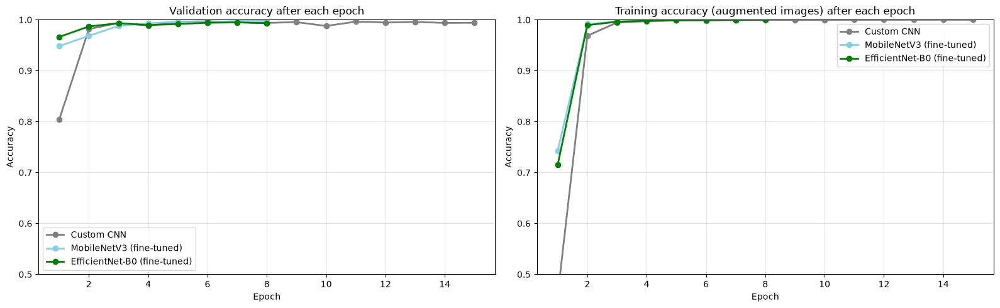

In [55]:
histories = {'Custom CNN': cnn_hist, 'MobileNetV3 (fine-tuned)': mobilenet_hist,
             'EfficientNet-B0 (fine-tuned)': effnet_hist}
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for (name, h), colour in zip(histories.items(), ['gray', 'skyblue', 'green']):
    axes[0].plot(h['Epoch'], h['Val Acc'], marker='o', linewidth=2, color=colour, label=name)
    axes[1].plot(h['Epoch'], h['Train Acc'], marker='o', linewidth=2, color=colour, label=name)
axes[0].set_title('Validation accuracy after each epoch'); axes[1].set_title('Training accuracy (augmented images) after each epoch')
for ax in axes:
    ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy'); ax.set_ylim(0.5, 1.0); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

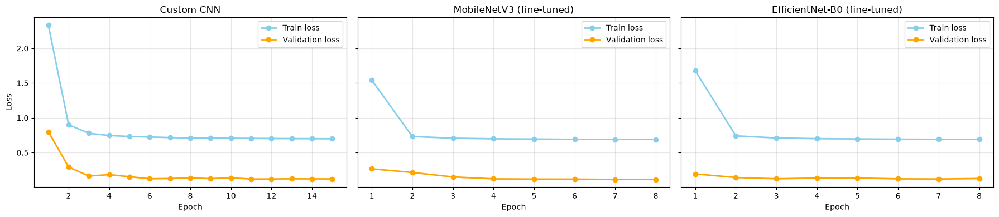

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h['Epoch'], h['Train Loss'], marker='o', color='skyblue', linewidth=2, label='Train loss')
    ax.plot(h['Epoch'], h['Val Loss'], marker='o', color='orange', linewidth=2, label='Validation loss')
    ax.set_title(name); ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=0.3)
axes[0].set_ylabel('Loss')
plt.tight_layout()
plt.show()

- **The pretrained networks start higher:** after one epoch MobileNetV3 is at **94.8%** and EfficientNet-B0 at **96.6%**, against 80.4% for the custom CNN. But the custom CNN **catches up by epoch 2-3**, and all three end above 99%.
- **Final validation accuracy:** MobileNetV3 **99.75%**, custom CNN 99.40%, EfficientNet-B0 99.30%. The validation set has only **3,990 images from 133 tracks**, so **one difficult track changes the validation accuracy by up to 0.75 points**. The differences between these three models are within that noise, so the **test set (12,630 images) is the real judge**.
- Training accuracy reaches 100% for all models and the validation loss is flat from about epoch 5, so **more epochs would not help**: the models have learned what the data can teach.

### Comparing the models on the test set

In [57]:
comparison = pd.DataFrame(results).set_index('Model')
comparison

,Approach,Input size,Test Accuracy,Macro F1,Top-3 Accuracy,Test errors,Images / second (test),Parameters (M),Epochs,Train minutes,Val Accuracy
Model,,,,,,,,,,,
Random Forest (simple features),"Colour, size, contrast, sharpness columns",NaN,0.1644,0.1156,0.3497,10554,NaN,NaN,NaN,NaN,NaN
Custom CNN,Trained from scratch,64.0,0.9983,0.9977,0.9998,22,2676.0,1.18,15.0,5.1,0.9940
MobileNetV3 (feature extractor),"Transfer learning, frozen CNN + grid search on...",128.0,0.7333,0.6535,0.9070,3368,NaN,NaN,NaN,NaN,NaN
MobileNetV3 (fine-tuned),"Transfer learning, fine-tuned",128.0,0.9918,0.9853,0.9987,104,1871.0,4.26,8.0,8.9,0.9975
EfficientNet-B0 (fine-tuned),"Transfer learning, fine-tuned",128.0,0.9960,0.9953,0.9995,50,1388.0,4.06,8.0,13.4,0.9930


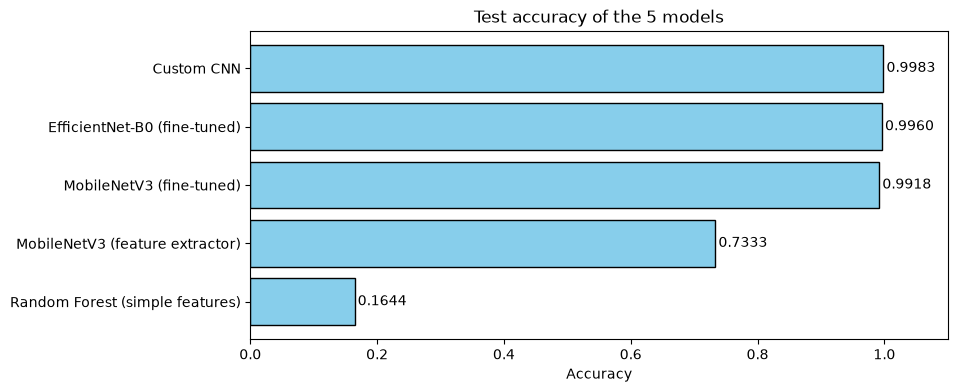

In [58]:
comp = comparison.sort_values('Test Accuracy')
plt.figure(figsize=(9, 4))
plt.barh(comp.index, comp['Test Accuracy'], color='skyblue', edgecolor='black')
for i, v in enumerate(comp['Test Accuracy']):
    plt.text(v + 0.005, i, f'{v:.4f}', va='center')
plt.xlim(0, 1.1)
plt.title('Test accuracy of the 5 models')
plt.xlabel('Accuracy')
plt.show()

- **The custom CNN is the best model: 99.83% accuracy, macro F1 0.998, 22 errors.** EfficientNet-B0 is second (99.60%, 50 errors) and MobileNetV3 third (99.18%, 104 errors, macro F1 0.985).
- **The small network wins** because it works at the images' **own resolution** (64 px), while the pretrained networks get blurry images upscaled to 128 px, and their ImageNet knowledge helps little for simple drawn symbols.
- **Speed and size also favour the custom CNN:** **1.18M parameters** and **2,676 images/second** on the laptop GPU, against 4.26M / 1,871 images/s for MobileNetV3 and 4.06M / 1,388 images/s for EfficientNet-B0. Training time: 5.1 vs 8.9 vs 13.4 minutes.
- Accuracy and macro F1 are almost equal for the best models, so **the small classes are recognised as well as the large ones** despite the 10.7x imbalance.

## Ensembles and Test-Time Augmentation
- **Test-time augmentation (TTA):** each test image is predicted 3 times, **as it is, zoomed in 10% and zoomed out 10%**, and the answers are averaged. Signs are seen at many distances, so a small zoom gives a second and third opinion. (The usual left-right flip is **not** used: it would turn "Keep left" into "Keep right".)
- **Soft Voting:** average the probabilities of the three trained CNNs (Custom CNN, MobileNetV3 and EfficientNet-B0). Different networks make different mistakes, so the average is often better than each one.
- **Stacking:** a Logistic Regression learns how much to trust each CNN for each class. It is trained on the **validation** set predictions (tracks the CNNs never trained on) and tested on the test set.

In [59]:
tta = {}
for name, model, size in [('Custom CNN', cnn, 64), ('MobileNetV3 (fine-tuned)', mobilenet, 128),
                          ('EfficientNet-B0 (fine-tuned)', effnet, 128)]:
    tta[name] = {'test': predict_probs(model, test_idx, size, tta=True, name=name + ' + TTA'),
                 'val': predict_probs(model, val_idx, size, tta=True)}
    add_result(name + ' + TTA', 'Zoom TTA (3 views)', tta[name]['test'], model=model, size=size)

vote_probs = np.mean([t['test'] for t in tta.values()], axis=0)
add_result('Soft Voting (3 CNNs + TTA)', 'Ensemble: average of probabilities', vote_probs)

,Model,Approach,Input size,Test Accuracy,Macro F1,Top-3 Accuracy,Test errors,Images / second (test)
0,Soft Voting (3 CNNs + TTA),Ensemble: average of probabilities,None,0.9968,0.9957,0.9998,41,None


In [60]:
from sklearn.linear_model import LogisticRegression

stack_val = np.hstack([np.log(t['val'] + 1e-6) for t in tta.values()])
stack_test = np.hstack([np.log(t['test'] + 1e-6) for t in tta.values()])
stacker = LogisticRegression(C=0.05, max_iter=3000)
stacker.fit(stack_val, y_val)
stack_probs = stacker.predict_proba(stack_test)
add_result('Stacking (3 CNNs + TTA)', 'Ensemble: logistic regression on CNN outputs', stack_probs)

,Model,Approach,Input size,Test Accuracy,Macro F1,Top-3 Accuracy,Test errors,Images / second (test)
0,Stacking (3 CNNs + TTA),Ensemble: logistic regression on CNN outputs,None,0.9964,0.9952,0.9997,46,None


In [61]:
final_table = pd.DataFrame(results).set_index('Model')
final_table[['Approach', 'Test Accuracy', 'Macro F1', 'Top-3 Accuracy', 'Test errors', 'Parameters (M)', 'Train minutes', 'Images / second (test)']]

,Approach,Test Accuracy,Macro F1,Top-3 Accuracy,Test errors,Parameters (M),Train minutes,Images / second (test)
Model,,,,,,,,
Random Forest (simple features),"Colour, size, contrast, sharpness columns",0.1644,0.1156,0.3497,10554,NaN,NaN,NaN
Custom CNN,Trained from scratch,0.9983,0.9977,0.9998,22,1.18,5.1,2676.0
MobileNetV3 (feature extractor),"Transfer learning, frozen CNN + grid search on...",0.7333,0.6535,0.9070,3368,NaN,NaN,NaN
MobileNetV3 (fine-tuned),"Transfer learning, fine-tuned",0.9918,0.9853,0.9987,104,4.26,8.9,1871.0
EfficientNet-B0 (fine-tuned),"Transfer learning, fine-tuned",0.9960,0.9953,0.9995,50,4.06,13.4,1388.0
Custom CNN + TTA,Zoom TTA (3 views),0.9980,0.9973,0.9997,25,1.18,NaN,1678.0
MobileNetV3 (fine-tuned) + TTA,Zoom TTA (3 views),0.9918,0.9840,0.9993,103,4.26,NaN,934.0
EfficientNet-B0 (fine-tuned) + TTA,Zoom TTA (3 views),0.9960,0.9952,0.9995,51,4.06,NaN,566.0
Soft Voting (3 CNNs + TTA),Ensemble: average of probabilities,0.9968,0.9957,0.9998,41,NaN,NaN,NaN


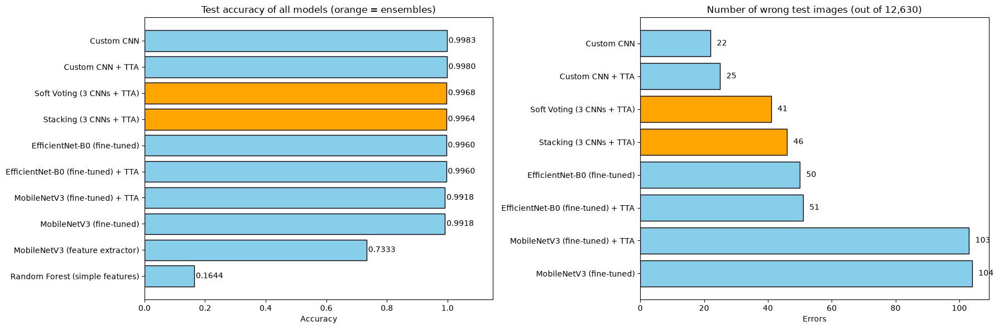

In [62]:
ft = final_table.sort_values('Test Accuracy')
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
colours = ['orange' if ('Voting' in n or 'Stacking' in n) else 'skyblue' for n in ft.index]
axes[0].barh(ft.index, ft['Test Accuracy'], color=colours, edgecolor='black')
for i, v in enumerate(ft['Test Accuracy']):
    axes[0].text(v + 0.005, i, f'{v:.4f}', va='center')
axes[0].set_xlim(0, 1.15); axes[0].set_title('Test accuracy of all models (orange = ensembles)'); axes[0].set_xlabel('Accuracy')
top = ft[ft['Test Accuracy'] > 0.9]
axes[1].barh(top.index, top['Test errors'], color=['orange' if ('Voting' in n or 'Stacking' in n) else 'skyblue' for n in top.index], edgecolor='black')
for i, v in enumerate(top['Test errors']):
    axes[1].text(v + 2, i, str(v), va='center')
axes[1].set_title(f'Number of wrong test images (out of {len(test_idx):,})'); axes[1].set_xlabel('Errors')
plt.tight_layout()
plt.show()

- **Test-time augmentation does not help here:** custom CNN 22 -> **25 errors**, MobileNetV3 104 -> 103, EfficientNet-B0 50 -> 51. The models already learned to handle zoom from the training augmentation, so extra zoomed views add nothing. They only cost time (custom CNN 2,676 -> 1,678 images/second).
- **Soft Voting: 99.68% (41 errors).** It is better than EfficientNet-B0 and MobileNetV3 alone, but **worse than the custom CNN alone**: averaging the best model with two weaker ones pulls it down.
- **Stacking: 99.64% (46 errors)**, also below the custom CNN. The logistic regression learns from only 3,990 validation images (133 tracks).
- All the CNN models are above 99%, so the differences between them are **a few dozen images out of 12,630**.

## Chosen Model
We choose the **Custom CNN (64 x 64, one prediction per image, no TTA)** as the final model:
- **Highest test accuracy (99.83%) and macro F1 (0.998)**, with only 22 errors on 12,630 test images. No ensemble and no TTA did better.
- **Smallest and fastest model**: 1.18 million parameters (a 4.7 MB file), 2,676 images per second. A car has to read signs from a video stream in real time on a small onboard computer, so speed and size matter.

In [63]:
from sklearn.metrics import classification_report, confusion_matrix

FINAL_NAME = 'Custom CNN'
final_model, FINAL_SIZE, FINAL_TTA = cnn, 64, False    # TTA did not help this model, so one view per image
final_probs = cnn_probs
final_pred = final_probs.argmax(1)
print(FINAL_NAME, {k: round(v, 4) for k, v in scores(y_test, final_probs).items()})
report = pd.DataFrame(classification_report(y_test, final_pred, target_names=class_names, output_dict=True, digits=4)).T
report.loc[['accuracy', 'macro avg', 'weighted avg']]

Custom CNN {'Test Accuracy': 0.9983, 'Macro F1': 0.9977, 'Top-3 Accuracy': 0.9998}


,precision,recall,f1-score,support
accuracy,0.998258,0.998258,0.998258,0.998258
macro avg,0.997609,0.997859,0.997714,12630.000000
weighted avg,0.998280,0.998258,0.998259,12630.000000


In [64]:
per_class = report.iloc[:43].sort_values('f1-score')
per_class['Train images'] = [np.sum(y_all[train_idx] == class_names.index(c)) for c in per_class.index]
per_class.head(12).round(4)

,precision,recall,f1-score,support,Train images
21: Double curve,0.9574,1.0000,0.9783,90.0,300
22: Bumpy road,1.0000,0.9750,0.9873,120.0,360
40: Roundabout,0.9889,0.9889,0.9889,90.0,330
37: Go straight or left,1.0000,0.9833,0.9916,60.0,180
30: Beware of ice / snow,0.9868,1.0000,0.9934,150.0,390
18: General caution,1.0000,0.9872,0.9935,390.0,1080
3: Speed limit 60,1.0000,0.9889,0.9944,450.0,1260
5: Speed limit 80,0.9921,0.9984,0.9953,630.0,1680
36: Go straight or right,0.9917,1.0000,0.9959,120.0,360
25: Road work,0.9938,1.0000,0.9969,480.0,1350


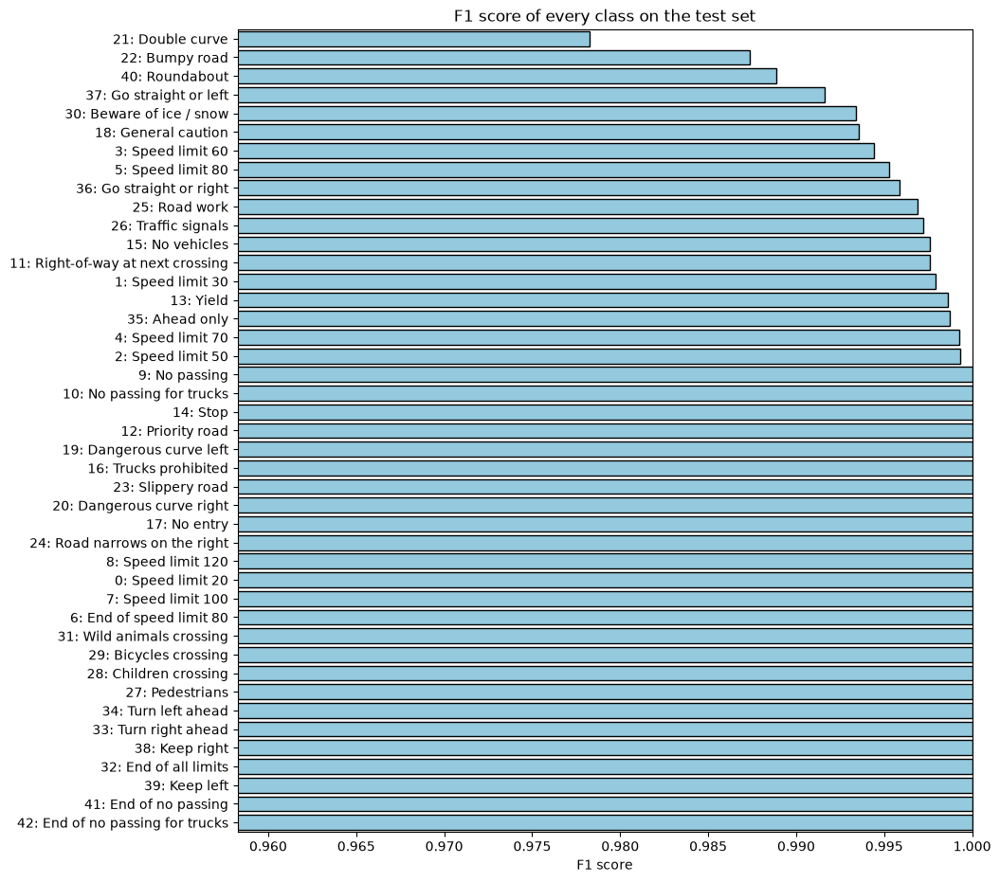

In [65]:
plt.figure(figsize=(10, 11))
sns.barplot(x=per_class['f1-score'], y=per_class.index, color='skyblue', edgecolor='black')
plt.xlim(per_class['f1-score'].min() - 0.02, 1.0)
plt.title('F1 score of every class on the test set')
plt.xlabel('F1 score'); plt.ylabel('')
plt.show()

In [66]:
cm = confusion_matrix(y_test, final_pred, labels=range(43))
pairs = []
for t in range(43):
    for p in range(43):
        if t != p and cm[t, p] > 0:
            pairs.append([class_names[t], class_names[p], cm[t, p], round(cm[t, p] / cm[t].sum() * 100, 2)])
pairs = pd.DataFrame(pairs, columns=['True class', 'Predicted as', 'Images', '% of the true class']).sort_values('Images', ascending=False)
pairs.head(15)

,True class,Predicted as,Images,% of the true class
1,3: Speed limit 60,5: Speed limit 80,5,1.11
7,18: General caution,21: Double curve,4,1.03
9,22: Bumpy road,25: Road work,3,2.50
4,11: Right-of-way at next crossing,30: Beware of ice / snow,2,0.48
3,5: Speed limit 80,1: Speed limit 30,1,0.16
2,4: Speed limit 70,1: Speed limit 30,1,0.15
0,2: Speed limit 50,1: Speed limit 30,1,0.13
5,13: Yield,40: Roundabout,1,0.14
6,15: No vehicles,13: Yield,1,0.48
8,18: General caution,26: Traffic signals,1,0.26


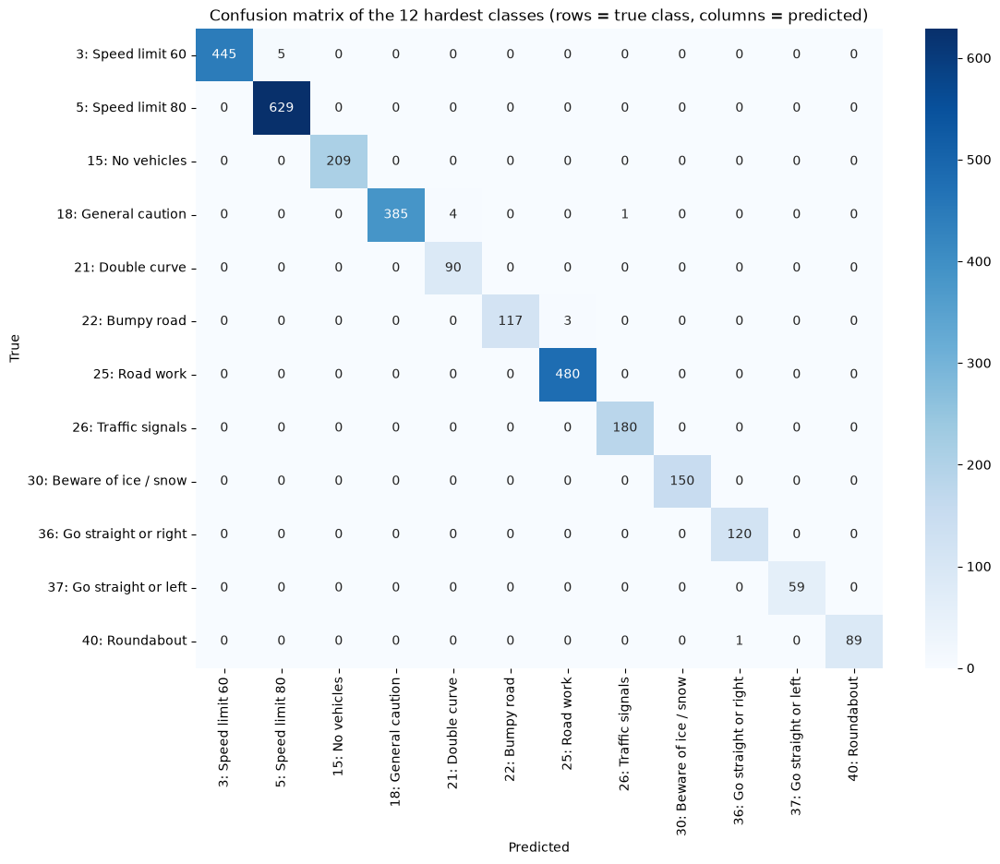

In [67]:
# confusion matrix of the 12 classes with the lowest F1
hard = sorted(class_names.index(c) for c in per_class.head(12).index)
plt.figure(figsize=(12, 9))
sns.heatmap(pd.DataFrame(cm[np.ix_(hard, hard)], index=[class_names[i] for i in hard], columns=[class_names[i] for i in hard]),
            annot=True, fmt='d', cmap='Blues')
plt.title('Confusion matrix of the 12 hardest classes (rows = true class, columns = predicted)')
plt.ylabel('True'); plt.xlabel('Predicted')
plt.show()

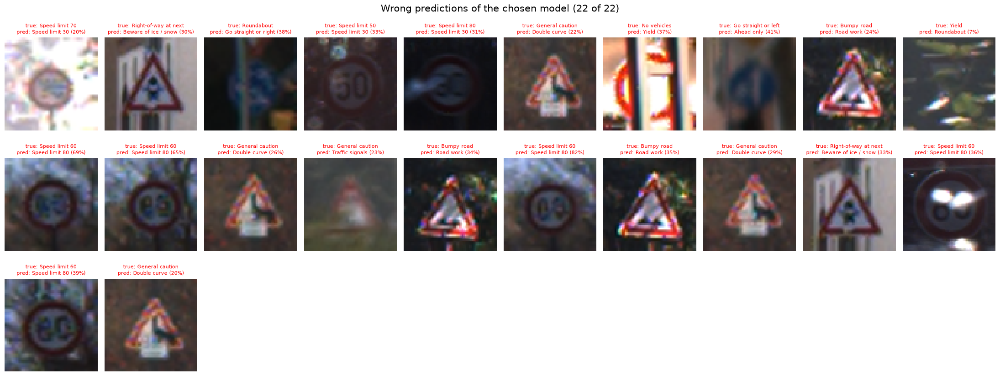

In [68]:
# all wrong predictions (or 30 of them)
wrong = np.where(final_pred != y_test)[0]
show = wrong if len(wrong) <= 30 else np.sort(rng.choice(wrong, 30, replace=False))
cols = 10
fig, axes = plt.subplots(int(np.ceil(len(show) / cols)), cols, figsize=(22, 2.9 * int(np.ceil(len(show) / cols))), squeeze=False)
for ax in axes.ravel(): ax.axis('off')
for ax, k in zip(axes.ravel(), show):
    ax.imshow(X[test_idx[k]])
    ax.set_title(f'true: {SIGN_NAMES[y_test[k]][:20]}\npred: {SIGN_NAMES[final_pred[k]][:20]} ({final_probs[k].max():.0%})', fontsize=8, color='red')
plt.suptitle(f'Wrong predictions of the chosen model ({len(show)} of {len(wrong)})', fontsize=15)
plt.tight_layout()
plt.show()

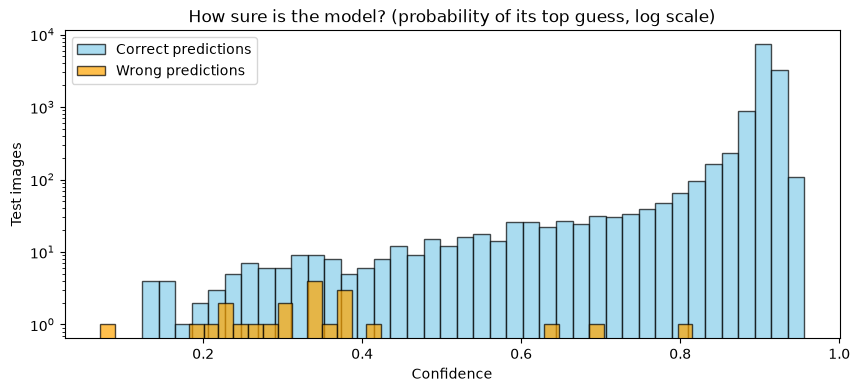

Median confidence -> correct: 0.909 | wrong: 0.333


In [69]:
conf = final_probs.max(1)
plt.figure(figsize=(10, 4))
plt.hist(conf[final_pred == y_test], bins=40, alpha=0.7, color='skyblue', edgecolor='black', label='Correct predictions')
plt.hist(conf[final_pred != y_test], bins=40, alpha=0.7, color='orange', edgecolor='black', label='Wrong predictions')
plt.yscale('log')
plt.title('How sure is the model? (probability of its top guess, log scale)')
plt.xlabel('Confidence'); plt.ylabel('Test images'); plt.legend()
plt.show()
print('Median confidence -> correct:', round(np.median(conf[final_pred == y_test]), 3), '| wrong:', round(np.median(conf[final_pred != y_test]), 3))

**Result**
- On the **12,630 test images**, the model is right **99.83%** of the time (**22 errors**), and the right sign is in its **top 3 for 99.98%** of the images. Macro precision 0.9976, macro recall 0.9979.
- **Every class has F1 of 0.978 or more.** The lowest are **Double curve (0.978, precision 0.957, because 4 General caution images were predicted as Double curve)**, **Bumpy road (0.987)**, **Roundabout (0.989)** and **Go straight or left (0.992)**.
- **Most frequent mistakes:** **Speed limit 60 -> 80 (5 images)**, **General caution -> Double curve (4)**, **Bumpy road -> Road work (3)**, Right-of-way -> Beware of ice / snow (2), and three single speed limits read as 30. These are look-alike signs from the same group (same shape and colour), as expected from Part 1.
- **Looking at all 22 wrong images**, most are **hard even for a person**: very dark or blurry digits (the "60"s really look like "80"s), a "No vehicles" sign almost hidden behind a pole, blurred blue signs, an over-exposed "70", and a "Yield" image that shows only leaves (the model was 7% sure). The 4 "General caution" errors all show a triangle whose picture looks like a curve, so these images are either unclear or **wrongly labelled**.
- **Confidence:** correct predictions have a median confidence of **0.909**, wrong ones only **0.333**. (Because of label smoothing, the model's highest confidence is about 0.9, so 0.9 means "very sure".) **The confidence can be trusted**, which we use in Part 3.

### Using the model on a new image
`predict_sign()` takes the path of any traffic sign image and returns the **3 most likely signs** with their probabilities.

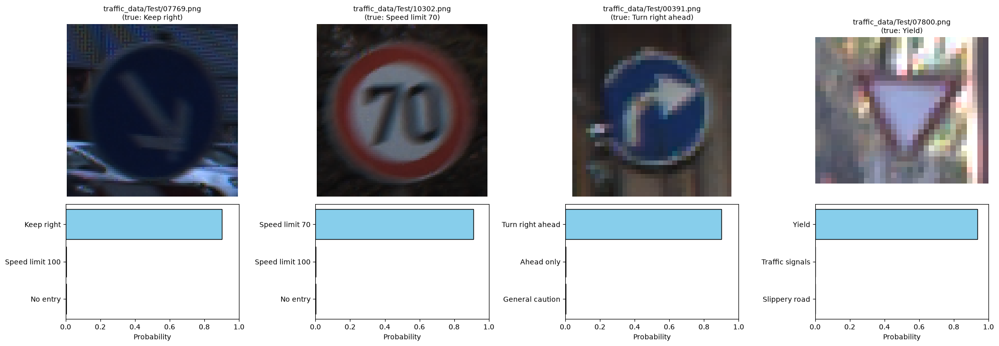

In [70]:
def predict_sign(path, model=final_model, size=FINAL_SIZE, top=3):
    img = load_and_resize(path)
    x = torch.from_numpy(img).to(device).permute(2, 0, 1)[None].float()
    model.eval()
    p = 0
    with torch.no_grad(), torch.autocast(device_type=device, dtype=torch.bfloat16):
        views = TTA_VIEWS if FINAL_TTA else [1.0]
        for v in views:
            z = torch.zeros(1, device=device)
            xv = (affine(x, z, torch.full((1,), v, device=device), z, z) - MEAN) / STD
            xv = F.interpolate(xv, size=(size, size), mode='bilinear', align_corners=False) if size != CACHE_SIZE else xv
            p = p + model(xv.contiguous(memory_format=torch.channels_last)).float().softmax(1)[0].cpu().numpy() / len(views)
    best = p.argsort()[::-1][:top]
    return pd.DataFrame({'Sign': [SIGN_NAMES[i] for i in best], 'Probability': p[best].round(4)})

fig, axes = plt.subplots(2, 4, figsize=(20, 7), gridspec_kw={'height_ratios': [3, 2]})
for c, k in enumerate(rng.choice(len(test_idx), 4, replace=False)):
    path = df['Path'].iat[test_idx[k]]
    res = predict_sign(path)
    axes[0, c].imshow(Image.open(path)); axes[0, c].axis('off')
    axes[0, c].set_title(f'{path}\n(true: {SIGN_NAMES[y_test[k]]})', fontsize=10)
    axes[1, c].barh(res['Sign'][::-1], res['Probability'][::-1], color='skyblue', edgecolor='black')
    axes[1, c].set_xlim(0, 1); axes[1, c].set_xlabel('Probability')
plt.tight_layout()
plt.show()

In [71]:
torch.save({'model_state': final_model.state_dict(), 'architecture': 'CustomCNN (class defined in this notebook)', 'classes': SIGN_NAMES,
            'image_size': FINAL_SIZE, 'cache_size': CACHE_SIZE, 'tta': FINAL_TTA,
            'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225]},
           os.path.join(MODEL_DIR, 'final_traffic_sign_classifier.pt'))
print('Saved', os.path.join(MODEL_DIR, 'final_traffic_sign_classifier.pt'))

Saved traffic_models\final_traffic_sign_classifier.pt


# Part 3: Suggestions for Using the Model in a Driver-Assistance System
## 1. Can the system know when it is unsure?

In [72]:
rows = []
for t in [0, 0.5, 0.6, 0.7, 0.8, 0.85]:
    keep = conf >= t
    rows.append([t, round(keep.mean() * 100, 2), round((final_pred[keep] == y_test[keep]).mean() * 100, 3),
                 int((final_pred[keep] != y_test[keep]).sum()), int((~keep).sum()),
                 int((final_pred[~keep] != y_test[~keep]).sum())])
pd.DataFrame(rows, columns=['Confidence at least', '% of images accepted', 'Accuracy on accepted %', 'Errors accepted',
                            'Images held back', 'Errors among held back'])

,Confidence at least,% of images accepted,Accuracy on accepted %,Errors accepted,Images held back,Errors among held back
0,0.00,100.00,99.826,22,0,0
1,0.50,98.91,99.976,3,138,19
2,0.60,98.26,99.976,3,220,19
3,0.70,97.25,99.992,1,347,21
4,0.80,95.72,99.992,1,540,21
5,0.85,93.59,100.000,0,809,22


## 2. Using all the frames of a track (the car sees each sign many times)
A camera in a car sees the same sign in many video frames while driving towards it. The **validation set** contains whole tracks, so we can check what happens if the system **averages its predictions over the frames of a track**, as a real car would do.

In [73]:
val_probs_final = predict_probs(final_model, val_idx, FINAL_SIZE, tta=FINAL_TTA)
vdf = df.loc[val_idx, ['TRACK', 'FRAME', 'ClassId']].copy()
vdf['CORRECT'] = (val_probs_final.argmax(1) == y_val).astype(int)
frame_acc = vdf.groupby('FRAME')['CORRECT'].mean() * 100

track_rows = []
for n_frames in [1, 3, 5, 10, 30]:
    ok = []
    for t, g in vdf.groupby('TRACK'):
        first = g.sort_values('FRAME').index[:n_frames]          # the first frames = when the sign is still far away
        pos = np.searchsorted(val_idx, first)
        ok.append(val_probs_final[pos].mean(0).argmax() == g['ClassId'].iat[0])
    track_rows.append([n_frames, round(np.mean(ok) * 100, 2), len(ok) - int(np.sum(ok))])
print('Accuracy on single validation images:', round(vdf['CORRECT'].mean() * 100, 2), '%')
pd.DataFrame(track_rows, columns=['Frames averaged (from the first = farthest)', 'Track accuracy %', 'Tracks wrong'])

Accuracy on single validation images: 99.4 %


,Frames averaged (from the first = farthest),Track accuracy %,Tracks wrong
0,1,98.50,2
1,3,99.25,1
2,5,99.25,1
3,10,99.25,1
4,30,99.25,1


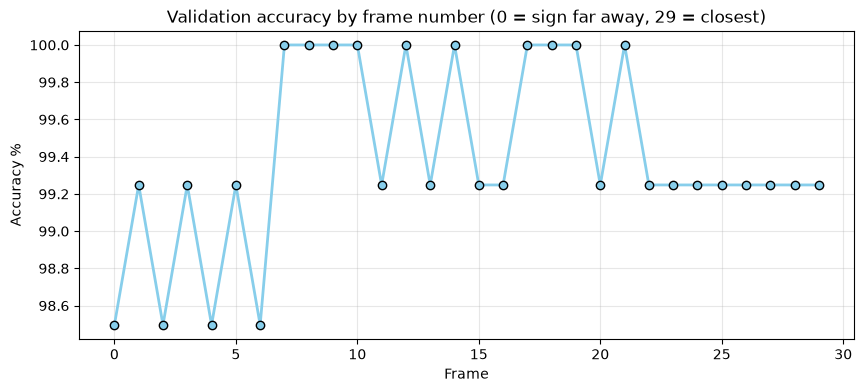

In [74]:
plt.figure(figsize=(10, 4))
plt.plot(frame_acc.index, frame_acc.values, marker='o', color='skyblue', markeredgecolor='black', linewidth=2)
plt.title('Validation accuracy by frame number (0 = sign far away, 29 = closest)')
plt.xlabel('Frame'); plt.ylabel('Accuracy %'); plt.grid(alpha=0.3)
plt.show()

## 3. Fair comparison: Do dark, small or blurry images hurt the model?
Some signs are naturally darker or smaller in the images than others, and some classes are just harder, so comparing "dark images" against "all images" would mix the effect of the **sign** with the effect of the **image quality**. To be fair, each image is compared **only with images of the same class**:
- an image is "dark" if it is in the darkest 20% **of its own class**, "low contrast" / "blurry" / "small" if it is in the lowest 20% of contrast / sharpness / width **of its own class**;
- the error rate of these images is compared with the other images of the same class, and the difference is averaged over the classes.

The chosen model makes very few mistakes, so the **error rate** (% wrong) is shown instead of accuracy.

In [75]:
test_df = df.loc[test_idx, ['ClassId', 'BRIGHTNESS', 'CONTRAST', 'SHARPNESS', 'Width']].copy()
test_df['WRONG'] = (final_pred != y_test).astype(int)
low20 = lambda col: test_df.groupby('ClassId')[col].transform(lambda s: s <= s.quantile(0.2)).astype(bool)
test_df['DARK'] = low20('BRIGHTNESS')
test_df['BRIGHT'] = test_df.groupby('ClassId')['BRIGHTNESS'].transform(lambda s: s >= s.quantile(0.8)).astype(bool)
test_df['LOW CONTRAST'] = low20('CONTRAST')
test_df['BLURRY'] = low20('SHARPNESS')
test_df['SMALL'] = low20('Width')

fair = []
for flag in ['DARK', 'BRIGHT', 'LOW CONTRAST', 'BLURRY', 'SMALL']:
    g = test_df.groupby(['ClassId', flag])['WRONG'].mean().unstack().reindex(columns=[False, True]).dropna()
    diff = (g[True] - g[False]) * 100
    fair.append([flag, int(test_df[flag].sum()), round(test_df.loc[test_df[flag], 'WRONG'].mean() * 100, 2),
                 round(test_df.loc[~test_df[flag], 'WRONG'].mean() * 100, 2), round(diff.mean(), 2), len(g),
                 int((diff > 0).sum()), int((diff < 0).sum())])
pd.DataFrame(fair, columns=['Image group', 'Test images', 'Error rate in group %', 'Error rate of the rest %',
                            'Within-class difference (points)', 'Classes compared', 'Classes where group is worse',
                            'Classes where group is better'])

,Image group,Test images,Error rate in group %,Error rate of the rest %,Within-class difference (points),Classes compared,Classes where group is worse,Classes where group is better
0,DARK,2542,0.08,0.20,-0.08,43,2,9
1,BRIGHT,2533,0.04,0.21,-0.25,43,1,10
2,LOW CONTRAST,2551,0.20,0.17,0.21,43,4,7
3,BLURRY,2538,0.20,0.17,0.22,43,4,7
4,SMALL,2830,0.49,0.08,0.41,43,7,4


## 4. Do classes with fewer training images do worse?
Comparing small and large classes directly is not fair either, because the small classes are often rarer, more unusual signs. So the classes are compared **inside the same sign family** (same shape and colour, e.g. red-ring circles, red triangles, blue circles).

In [76]:
cls = pd.DataFrame({'Train images': np.bincount(y_all[train_idx], minlength=43),
                    'Test error %': [(final_pred[y_test == c] != c).mean() * 100 for c in range(43)],
                    'Family': [f"{SHAPES[meta_idx.loc[c, 'ShapeId']]} / {COLOURS[meta_idx.loc[c, 'ColorId']]}" for c in range(43)]},
                   index=class_names)
cls['Small class'] = cls.groupby('Family')['Train images'].transform(lambda s: s < s.median())
fam = cls.groupby(['Family', 'Small class'])['Test error %'].mean().unstack().dropna()
fam.columns = ['Large classes in family: error %', 'Small classes in family: error %']
fam['Classes in family'] = cls.groupby('Family').size()
print('Correlation between training images and test error, over the 43 classes:', round(cls['Train images'].corr(cls['Test error %']), 3))
fam.round(3)

Correlation between training images and test error, over the 43 classes: -0.092


,Large classes in family: error %,Small classes in family: error %,Classes in family
Family,,,
circle / blue,0.000,0.694,8
circle / red,0.063,0.265,13
triangle / red,0.220,0.357,15


## 5. Which signs need more or better images?

In [77]:
worst = cls.sort_values('Test error %', ascending=False).head(10)[['Train images', 'Test error %']].round(2)
worst['Most often predicted as'] = [pairs[pairs['True class'] == c]['Predicted as'].iloc[0] if (pairs['True class'] == c).any() else '-' for c in worst.index]
worst

,Train images,Test error %,Most often predicted as
22: Bumpy road,360,2.50,25: Road work
37: Go straight or left,180,1.67,35: Ahead only
18: General caution,1080,1.28,21: Double curve
40: Roundabout,330,1.11,36: Go straight or right
3: Speed limit 60,1260,1.11,5: Speed limit 80
11: Right-of-way at next crossing,1200,0.48,30: Beware of ice / snow
15: No vehicles,570,0.48,13: Yield
5: Speed limit 80,1680,0.16,1: Speed limit 30
4: Speed limit 70,1770,0.15,1: Speed limit 30
13: Yield,1950,0.14,40: Roundabout


## Suggestions for the Driver-Assistance Team

**A note on fair comparison:** some signs are filmed in darker places or from further away than others, so the effect of image quality was checked **inside each class** (dark images were compared only with images of the same sign), and the effect of class size **inside each sign family** (same shape and colour).

**1. Act only on confident predictions (the most useful rule).**
- With confidence **at least 0.7**, the system answers for **97.3% of the images** and is right **99.992%** of the time (**1 error in 12,283 images**). At **0.85 or more**: 93.6% of the images, **no error at all**.
- The **347 images below 0.7 contain 21 of the 22 errors**. For these, the system should **wait for the next video frames** instead of showing a sign to the driver.

**2. Combine the frames of a track (the car sees each sign many times).** On the validation tracks, one image alone gives 99.4% accuracy and **98.5% of the tracks are right from the very first (farthest) frame**. **Averaging the first 3 frames already gives 99.25% of the tracks right (132 of 133)**, and the result is the same with 5, 10 or 30 frames. The one track that stays wrong is a "Dangerous curve left" read as "Slippery road" in 19 of its 30 frames. This class has only **7 tracks** in the whole data (6 for training). So the system should **decide after a few frames, not after a single image**.

**3. Image quality: distance matters, light does not.** Fair comparison within each class:
- **Dark images are not worse** (-0.08 points, better in 9 classes and worse in only 2), and very bright ones are not worse either (-0.25). The brightness and contrast augmentation worked.
- **Small images (sign far away) are the real weakness:** error rate **0.49% vs 0.08%** for the rest, **+0.41 points within class**, worse in 7 classes. Low-contrast and blurry images are slightly worse (+0.21 / +0.22 points).
- So a **higher-resolution camera or a zoomed second camera** would help more than better night vision, and the system should trust its predictions more as the sign gets closer.

**4. Collect more examples of the small classes.** Over all 43 classes, training size and error are hardly related (correlation -0.09). But **inside the same sign family the smaller classes are worse**: blue circles **0.69% vs 0.00%** error, red circles **0.27% vs 0.06%**, red triangles **0.36% vs 0.22%**. The classes to strengthen first are **Bumpy road (2.5% error, 360 training images), Go straight or left (1.7%, 180 images), Roundabout (1.1%, 330 images)** and **Dangerous curve left (only 7 tracks)**. More **different physical signs** (tracks) are worth more than more frames of the same sign.

**5. Extra care for speed limits.** The most frequent error is **Speed limit 60 read as 80** (5 images, 1.1% of the 60 signs). This is the **dangerous direction** (the car would think it may drive faster). Speed limits should need agreement over several frames, and should be checked against **map / GPS speed-limit data** when it is available.

**6. Next steps for the data.** Check the labels of the training images where the model strongly disagrees with the label (like the "General caution" images that show a curve). The dataset contains only **German** signs in daylight-like conditions, so before using the model in other countries or in rain, snow and night, new data from those conditions must be added and tested.

# Model Comparison Report
**Goal:** Recognise the type of traffic sign in an image (**43 classes**). The data has 39,209 training images (1,307 tracks of 30 frames) and 12,630 official test images. The training images were split **by track** into **35,219 for training and 3,990 for validation** (about 10% of the tracks of every class), so no physical sign is in both. All results below are on the **official test set**, which was never used for training or for choosing settings.

| Model | Approach | Test Accuracy | Macro F1 | Top-3 Accuracy | Test errors (of 12,630) | Train time | Speed (images/s) |
|---|---|---|---|---|---|---|---|
| Random Forest (simple features) | Colour, size, contrast, sharpness columns | 16.4% | 0.116 | 35.0% | 10,554 | < 1 min | - |
| **Custom CNN (64 px) (chosen)** | CNN trained from scratch, 15 epochs | **99.83%** | **0.998** | **99.98%** | **22** | 5.1 min | **2,676** |
| MobileNetV3 (feature extractor) | Frozen pretrained CNN + grid-searched last layer | 73.3% | 0.654 | 90.7% | 3,368 | 0.5 min | - |
| MobileNetV3 (fine-tuned) | Transfer learning, 8 epochs, 128 px | 99.18% | 0.985 | 99.87% | 104 | 8.9 min | 1,871 |
| EfficientNet-B0 (fine-tuned) | Transfer learning, 8 epochs, 128 px | 99.60% | 0.995 | 99.95% | 50 | 13.4 min | 1,388 |
| Custom CNN + TTA | + 2 zoomed views | 99.80% | 0.997 | 99.97% | 25 | - | 1,678 |
| MobileNetV3 + TTA | + 2 zoomed views | 99.18% | 0.984 | 99.93% | 103 | - | 934 |
| EfficientNet-B0 + TTA | + 2 zoomed views | 99.60% | 0.995 | 99.95% | 51 | - | 566 |
| Soft Voting (3 CNNs + TTA) | Average of probabilities | 99.68% | 0.996 | 99.98% | 41 | - | - |
| Stacking (3 CNNs + TTA) | Logistic regression on CNN outputs | 99.64% | 0.995 | 99.97% | 46 | - | - |

**Conclusions**
- **Pixels beat hand-made features:** a Random Forest on colour and size columns gets 16.4%; every CNN gets above 99%.
- **Splitting by track is essential:** a random split made the Random Forest look like 69.2% when it really reaches about 16%. All CNN results are on tracks and test images the models never saw.
- **For traffic signs a small CNN trained from scratch is enough, and is the best:** 99.83% at 64 px, better than fine-tuned MobileNetV3 (99.18%) and EfficientNet-B0 (99.60%), and 1.5-2 times faster. Signs are standard drawings, unlike food photos, where transfer learning was the key.
- **A frozen ImageNet network is not enough** (73.3%): its features do not separate small digits and pictograms. Fine-tuning fixes this (+25.9 points for MobileNetV3).
- **TTA and ensembles did not beat the single custom CNN**: the training augmentation already covers zoom, and averaging with weaker models adds their mistakes.
- **Chosen model: Custom CNN**, saved as `traffic_models/final_traffic_sign_classifier.pt` with the class names and usable on any image through `predict_sign()`. With confidence above 0.7 it is right **99.992%** of the time on 97.3% of the images, and combining 3 frames of a track recognises 132 of 133 validation signs.

# Challenges Faced

| # | Challenge | Technique used | Reason |
|---|---|---|---|
| 1 | The zip contains every folder twice (`Train` / `train`, `Test` / `test`, `Meta` / `meta`), and Windows does not allow two folder names that differ only in upper / lower case | Compared the CRC of every file pair (all identical) and extracted only the upper-case folders | Avoids a broken extraction and double-counting the images |
| 2 | The data has no sign names, only ClassId 0-42 | Added the official GTSRB names and checked them against the shape and colour codes in `Meta.csv` | Readable plots, reports and predictions |
| 3 | The 30 frames of one track are almost the same image (data leakage) | Validation split **by track**; Random Forest cross-validation with KFold vs GroupKFold to measure the effect (69.2% vs 15.7%) | A random split would give a falsely high score |
| 4 | The smallest classes have only 7 tracks; a 10-fold group split left 3 classes out of the validation set (found when stacking failed) | Picked about 10% of the tracks **of every class**, at least 1 track per class | Every class must be in the validation set for monitoring and for stacking |
| 5 | Class imbalance (210 to 2,250 training images per class) | Class-stratified validation split, macro F1 next to accuracy, fair comparison of small vs large classes **inside each sign family** | The model must not ignore rare but important signs |
| 6 | Very small, dark and blurry images (median 43 px, 85 images with brightness below 10) | Resized to 64 x 64; brightness / contrast / rotation / zoom / shift augmentation; outliers kept | A real car camera sees the same conditions |
| 7 | Left / right meaning: a flipped "Keep left" is a "Keep right" | **No horizontal flip** in training or TTA; TTA uses zoom instead | A flip would create wrong labels |
| 8 | 8 test images are exact copies of training images | Kept and reported (at most 0.06 points of accuracy) | Keeps the official test set complete and comparable |
| 9 | Frozen ImageNet features work badly on tiny signs (73.3%) | Fine-tuned the whole network, and trained a custom CNN at the images' own resolution | The models need features for digits and small pictograms |
| 10 | Long training on a laptop GPU, and the notebook shows no output while it runs | All images kept in GPU memory with augmentation on the GPU; trained models saved in `traffic_models/`; a progress log file | Fast training, and the notebook can be re-run without training again |
| 11 | Label smoothing keeps the highest confidence at about 0.9 | Confidence thresholds chosen at 0.7-0.85 (not 0.95) | Thresholds must match how the model's confidence is spread |